# Q1E | Train Polynomial Regression

> E. Repeat everything from part D with polynomial regression and using SGD. Using validation loss, explore if your model overfits/underfits the data and report your findings. Ensure reproducibility by using a seed.

Part D, which this repeats:

> Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization – try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.

**IMPORTANT**

This notebook uses only the train dataset, so no modeling decision is influenced by the test data (data snooping). Every score below is a cross validation score on the training rows.

# Answer Summary

**Cross validation and metric**
- 20 shared folds: four-fold cross validation cut 5 times, scored by RMSE in `Life Ladder` points, with the incomplete rows only ever on the training side. A change is real only when its Δrmse clears 1 SE.

**Polynomial regression: degree and expanded columns**
- By closed form, degree 2 on D's features is the only gain over D's model (-0.0117, SE 0.0041); from degree 3 training RMSE keeps falling while validation RMSE rises.
- SGD moves the degree to 4 (-0.0068, SE 0.0048 against degree 2): it stops long before the overfit least squares fit.

**Closed form**
- Solved by SVD: on repeated expanded columns `LinearRegression` breaks at degree 4 (about 2e11), SVD does not.

**Feature set**
- Retuned at degree 2: a hinge on `Log GDP per capita`, `Social support` raw, `Generosity` and `Negative affect` out. The carried closed form beats D's model on every fold (-0.0232, SE 0.0051).
- KNN wins the imputer tier at degree 2, but on the carried set dropping the incomplete rows beats it (-0.0027, SE 0.0024), so every model trains on the complete rows.

**Closed form vs SGD**
- At scikit-learn's defaults SGD matches the closed form at degree 2 (+0.0006, SE 0.0029); tuned at degree 4 it beats it (-0.0180, SE 0.0063).

**Other hyperparameters**
- The step decides at higher degrees: the step that works shrinks as the degree grows, and at degree 4 only `adaptive` at `eta0` 0.0001 is a candidate.
- Training longer helps at degree 4: `tol` 0.000001 is carried (0.4763), with up to 1428 epochs.

**Regularization**
- Small penalties change nothing: up to alpha 0.01 for Ridge and 0.001 for Lasso and Elastic Net, every run is within noise of no penalty.
- L1 bites first: Lasso is worse from alpha 0.01, Ridge only from alpha 1, and in Elastic Net more L1 costs more.
- Large penalties underfit, then predict the mean: Lasso from alpha 1 reaches Dummy's RMSE (1.1279 against 1.1281).

**Selected model**
- Elastic Net at `l1_ratio` 0.1 and alpha 0.01, picked as required: the lowest mean (0.4758), within noise of no penalty.
- Trained on the 1,374 complete rows and saved: training RMSE 0.4506, close to the folds' 0.4462.

**Loss by epoch**
- Learns fast, then holds: most of the drop comes in the first 10 epochs, and validation RMSE never turns back up.
- Drawn by refitting with `max_iter=k` on a log spaced set of epochs; the hint's loop restarts the schedule.

**Overfitting and underfitting**
- Degree 1 underfits: training and validation RMSE are high and almost level (0.5262 and 0.5302).
- The closed form overfits from degree 3; SGD does not up to degree 4: validation RMSE keeps falling with the degree while the training gap grows (0.4462 against 0.4758 at degree 4).
- Nothing for a penalty to cure: a penalty raises training RMSE without lowering validation RMSE.
- More epochs never overfit: at every degree the validation curve falls and holds.

**Reproducibility**
- Seed 42 for the fold cuts, the iterative imputer and every SGD model, including the refits behind the loss curves.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.experimental import enable_iterative_imputer  # makes IterativeImputer importable
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import Q1.consts as Q1_CONSTS
from Q1.utils import ScaledKNNImputer
from consts import SEED, CV_SPLITS, MAX_ITER, LEARNING_RATE_SCHEDULES, ETA0S, ALPHAS, L1_RATIOS, DEGREES, TOLS

from utils import (
	read_csv_to_df,
	STATISTICS,
	PLOTTING,
	PIPELINES,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)  # a diverging run would otherwise switch a whole table to 1e+12 style

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=Q1_CONSTS.TRAIN_PATH)

ATTRIBUTES = [column for column in train_df.columns if column != Q1_CONSTS.TARGET]
X, y = train_df[ATTRIBUTES], train_df[Q1_CONSTS.TARGET]

# Setup

## Folds

In [3]:
# Validation rows are complete rows only, as in the test file. The incomplete rows are added to the training side of
# every fold, so a model that imputes them and one that drops them are scored on the same validation rows.
complete = np.flatnonzero(X.notna().all(axis=1))
incomplete = np.flatnonzero(X.isna().any(axis=1))
cuts = RepeatedKFold(n_splits=CV_SPLITS, n_repeats=Q1_CONSTS.CV_REPEATS, random_state=SEED).split(complete)
FOLDS = [(np.concatenate([complete[train], incomplete]), complete[validation]) for train, validation in cuts]
DROP_FOLDS = [(train[np.isin(train, complete)], validation) for train, validation in FOLDS]  # the same folds without the incomplete rows

pd.DataFrame({
	'folds': [len(FOLDS), len(DROP_FOLDS)],
	'training rows': [f'{min(len(t) for t, _ in folds)} to {max(len(t) for t, _ in folds)}' for folds in (FOLDS, DROP_FOLDS)],
	'validation rows': [f'{min(len(v) for _, v in folds)} to {max(len(v) for _, v in folds)}' for folds in (FOLDS, DROP_FOLDS)],
}, index=['FOLDS (incomplete rows imputed)', 'DROP_FOLDS (incomplete rows dropped)'])

,folds,training rows,validation rows
FOLDS (incomplete rows imputed),20,1215 to 1216,343 to 344
DROP_FOLDS (incomplete rows dropped),20,1030 to 1031,343 to 344


## Runs

In [4]:
MEDIAN = SimpleImputer(strategy='median')  # Q1B's preprocessing note: fill a missing value with its attribute's median
RUNS = {}  # every cross validation result, keyed by name

def build(model, shapes=None, imputer=MEDIAN, degree=1, expand=None):
	"""The pipeline of one experiment: imputer, shapes, standardized columns, polynomial terms above degree 1, model (see
	PIPELINES.build_pipeline)."""
	return PIPELINES.build_pipeline(model=model, attributes=ATTRIBUTES, shapes=shapes, imputer=imputer, degree=degree, expand=expand)

def score(name, pipeline, folds=FOLDS):
	"""Cross validate a pipeline and keep its result under name."""
	RUNS[name] = PIPELINES.cv_rmse(pipeline=pipeline, X=X, y=y, folds=folds)

def table(names, baseline):
	"""The baseline's result, then each of names with its change against the baseline."""
	return STATISTICS.results_df(runs={name: RUNS[name] for name in [baseline, *names]}, baseline=baseline, folds=FOLDS)

def compare(baseline, candidate):
	"""The RMSE of both on every fold, beside the candidate's change on every fold."""
	PLOTTING.fold_comparison(runs=RUNS, baseline=baseline, candidate=candidate, folds=FOLDS, repeat_size=CV_SPLITS)

def deltas(names, baseline):
	"""Each of names' change against the baseline on every fold, one row each."""
	PLOTTING.fold_deltas(runs=RUNS, baseline=baseline, names=names, folds=FOLDS)

## Shapes

In [5]:
GDP, SOCIAL, LIFE_EXP, FREEDOM, GENEROSITY, CORRUPTION, POS_AFFECT, NEG_AFFECT = ATTRIBUTES
FITS = {attribute: STATISTICS.shape_fits(df=train_df, feature=attribute, target=Q1_CONSTS.TARGET) for attribute in ATTRIBUTES}

def shape(attribute, name):
	"""Q1B's shape of an attribute by name (ex 'hinge'), with the setting Q1B found, as a pipeline step."""
	return next(fit for fit in FITS[attribute] if fit.name == name).transformer

RAW = {attribute: 'passthrough' for attribute in ATTRIBUTES}
D_FEATURES = {  # D's carried feature set: 7 attributes in 8 columns
	GDP: 'passthrough',
	SOCIAL: shape(SOCIAL, 'reciprocal'),
	LIFE_EXP: shape(LIFE_EXP, 'floor'),
	FREEDOM: 'passthrough',
	GENEROSITY: shape(GENEROSITY, 'hinge'),
	CORRUPTION: 'passthrough',
	POS_AFFECT: 'passthrough',
	NEG_AFFECT: 'drop',
}

def counts(pipeline):
	"""How many columns the model of an unfitted pipeline gets, and how many of them are not exact combinations of the
	others, on the training rows of fold 1."""
	train, _ = FOLDS[0]
	columns = pipeline.regressor[:-1].fit_transform(X.iloc[train])
	ones = np.ones((len(columns), 1))  # the intercept's column: a column that only shifts the target is not independent either
	return {'columns': columns.shape[1], 'independent columns': np.linalg.matrix_rank(np.hstack([ones, columns])) - 1}

# Method

- **Metric:** RMSE in `Life Ladder` points, on the validation rows of each fold. The training RMSE next to it shows how much better a model fits the rows it was trained on.
- **Folds:** four-fold cross validation, cut 5 times from a new shuffle each time (`RepeatedKFold`, seed 42), so 20 folds. Every model is scored on the same 20 folds, so two models are compared fold by fold. Validation rows are the 1,374 complete rows only, as the test file has no missing values. The 185 incomplete rows always sit on the training side.
- **Noise:** Δrmse is the mean change in validation RMSE against the baseline, and SE its standard error, widened because the folds share most of their training rows (Nadeau and Bengio). Verdict: **candidate** when Δrmse is below -1 SE, **worse** when above +1 SE, **within noise** in between.
- **Carry rules:** a change is carried only when it is a candidate. Within noise, the simpler model stays: a feature change back to the raw attribute is taken, any other change is not, and a hyperparameter keeps its current value. Combined puts the carried feature changes together and is kept when its mean is below the strongest combination's.
- **Degree:** degrees 1 to 4 follow the carry rule against D's model, with one exception: the homework asks for polynomial regression, so when no degree of 2 or above is a candidate, the lowest mean at degree 2 or above is carried, stated as a tie. The degree is searched by closed form, which fits until the training error is as low as it can get, so a degree that overfits shows it on the validation rows. SGD stops once its training loss levels off, which can hide that, so SGD rechecks the degree together with its step size.
- **Selected model:** the homework asks for one regularized model, so the regularized setting with the lowest mean validation RMSE is selected, even when it only ties the others.
- **Drop One:** an attribute stays in the model only when dropping it raises the mean validation RMSE (see Drop One).
- **Pipeline:** every model is one pipeline that takes the 8 raw attributes: imputer, shapes, standardized columns, polynomial terms, standardized again, model. The target is standardized too and the predictions turned back into `Life Ladder` points. Each step is fit on the training rows of a fold only.
- **Polynomial terms:** at degree d, the columns are expanded into every product of up to d of them: squares, products of two columns, cubes, and so on (`PolynomialFeatures`, without a column of 1s, since the model fits its own intercept). The columns are standardized before the expansion, so a column and its square are not near copies, and again after it, so every expanded column is on the same scale for SGD's step and the penalty. Degree 1 is D's model.
- **Closed form:** least squares solved by SVD (`PIPELINES.SVDRegression`). Some expanded columns are exact combinations of others, so the least squares fit has many solutions, and SVD returns the one with the smallest coefficients. Closed Form on Polynomial Columns shows why `LinearRegression` is not used.
- **Overfitting and underfitting:** underfitting is training and validation RMSE both high and close, both falling when the model gets more flexible (a higher degree, a smaller penalty, more epochs). Overfitting is training RMSE still falling while validation RMSE rises, so the gap between them grows beyond degree 1's.
- **Shapes:** taken from Q1B's screen (`STATISTICS.shape_fits`) with the settings it found. Those settings were searched on all train rows, validation rows included, so shape results are a little optimistic.
- **Reproducibility:** seed 42 for the fold cuts, the iterative imputer and every SGD model (the order SGD visits the rows).
- **Optimism:** every choice is made on these folds, so their scores are a little optimistic. The test set gives the honest estimate.

# Baselines

## Dummy and Closed Form

Dummy, and D's closed form on its carried feature set (degree 1): the model every polynomial is compared against.

In [6]:
score('Dummy', build(DummyRegressor()))  # predicts the training mean of every fold
score('Closed form, D features', build(PIPELINES.SVDRegression(), D_FEATURES))  # least squares, solved by SVD

table(['Closed form, D features'], baseline='Dummy')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Dummy,1.1281,1.1085,NaN,NaN,,baseline
"Closed form, D features",0.5175,0.5186,-0.6105,0.0271,20 of 20,candidate


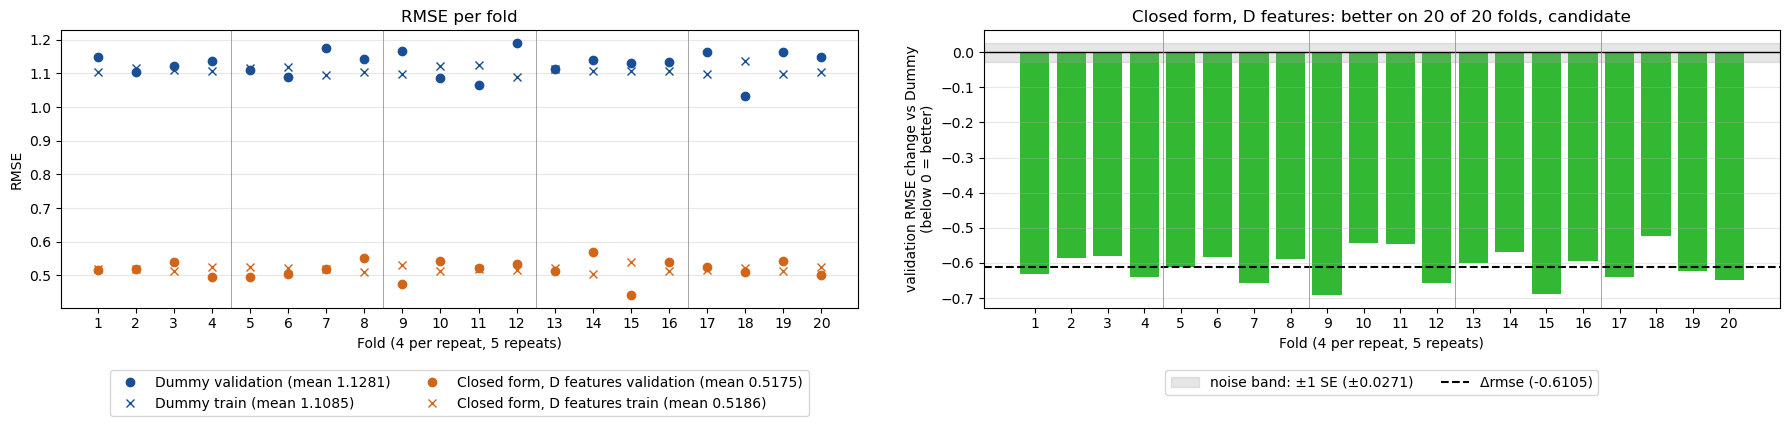

In [7]:
compare('Dummy', 'Closed form, D features')

### Notes / Observations

- D's model is the yardstick: its feature set, solved by SVD, scores 0.5175, and every polynomial below is compared with it.
- Nothing to cure at degree 1: training RMSE sits just above validation RMSE (0.5186 against 0.5175). A polynomial can only gain by following bends the straight lines miss.

# Closed Form on Polynomial Columns

D's feature set with every column expanded, at degrees 1 to 4, solved two ways: `LinearRegression` and SVD (`PIPELINES.SVDRegression`). Both find the least squares fit; they differ in how small a singular value has to be before it counts as 0. **columns** is how many columns the model gets, and **independent columns** how many of them are not exact combinations of the others, on the training rows of fold 1.

In [8]:
for degree in DEGREES:
	score(f'LinearRegression, degree {degree}', build(LinearRegression(), D_FEATURES, degree=degree))
	score(f'SVD, degree {degree}', build(PIPELINES.SVDRegression(), D_FEATURES, degree=degree))

pd.DataFrame([
	{
		**counts(build(PIPELINES.SVDRegression(), D_FEATURES, degree=degree)),
		'LinearRegression rmse': RUNS[f'LinearRegression, degree {degree}']['validation rmse'].mean(),
		'SVD rmse': RUNS[f'SVD, degree {degree}']['validation rmse'].mean(),
		'LinearRegression highest fold': RUNS[f'LinearRegression, degree {degree}']['validation rmse'].max(),
		'SVD highest fold': RUNS[f'SVD, degree {degree}']['validation rmse'].max(),
	}
	for degree in DEGREES
], index=pd.Index(DEGREES, name='degree'))

,columns,independent columns,LinearRegression rmse,SVD rmse,LinearRegression highest fold,SVD highest fold
degree,,,,,,
1,8,8,0.5175,0.5175,0.5688,0.5688
2,44,43,0.5058,0.5058,0.5456,0.5456
3,164,155,0.5965,0.5966,0.9470,0.9471
4,494,382,196159698379.7649,2.7380,1004987998143.1857,8.0406


### Notes / Observations

- `LinearRegression` breaks at degree 4, SVD does not: its validation RMSE reaches about 2e11, against 2.7380 for SVD. It treats rounding noise in the repeated columns as real and predicts wildly on new rows. This is a solver failure, not the model's, so SVD is the closed form from here on.
- The expanded columns repeat each other from degree 2 on, and more at each degree: at degree 4 only 382 of the 494 columns are independent.
- Where `LinearRegression` works (degrees 1 to 3), the two solvers agree within 0.0001, so SVD changes nothing else.

# Degree and Expanded Columns

Every pair of a set of expanded columns and a degree, by closed form, against D's model. The two sets:
- **D features:** D's carried feature set, every column expanded.
- **Raw:** the 8 raw attributes, every column expanded, so the polynomial terms have to find the bends D's shapes put in.

At degree 1 nothing is expanded, so `D features, degree 1` is D's model itself.

## Every Pair

In [9]:
YMAX = 1.2  # a little above Dummy's RMSE: a run that fails is drawn at the top of the chart instead of flattening the rest
SETS = {  # name: (shapes, the attributes whose columns are expanded, None for every column)
	'D features': (D_FEATURES, None),
	'Raw': (RAW, None),
}

PAIRS = {(expanded, degree): f'{expanded}, degree {degree}' for expanded in SETS for degree in DEGREES}
for (expanded, degree), name in PAIRS.items():
	shapes, expand = SETS[expanded]
	score(name, build(PIPELINES.SVDRegression(), shapes, degree=degree, expand=expand))

COUNTS = pd.DataFrame({
	'Closed form, D features': counts(build(PIPELINES.SVDRegression(), D_FEATURES)),
	**{
		name: counts(build(PIPELINES.SVDRegression(), SETS[expanded][0], degree=degree, expand=SETS[expanded][1]))
		for (expanded, degree), name in PAIRS.items()
	},
}).T
table(list(PAIRS.values()), baseline='Closed form, D features').join(COUNTS)

,rmse,train rmse,Δrmse,SE,better folds,verdict,columns,independent columns
"Closed form, D features",0.5175,0.5186,NaN,NaN,,baseline,8,8
"D features, degree 1",0.5175,0.5186,0.0000,0.0000,0 of 20,within noise,8,8
"D features, degree 2",0.5058,0.4900,-0.0117,0.0041,18 of 20,candidate,44,43
"D features, degree 3",0.5966,0.4359,0.0790,0.0911,8 of 20,within noise,164,155
"D features, degree 4",2.7380,0.3530,2.2205,0.9742,0 of 20,worse,494,382
"Raw, degree 1",0.5470,0.5455,0.0294,0.0069,1 of 20,worse,8,8
"Raw, degree 2",0.5126,0.4939,-0.0049,0.0050,17 of 20,within noise,44,44
"Raw, degree 3",0.5195,0.4294,0.0020,0.0145,11 of 20,within noise,164,164
"Raw, degree 4",1.0155,0.3014,0.4980,0.1318,0 of 20,worse,494,494


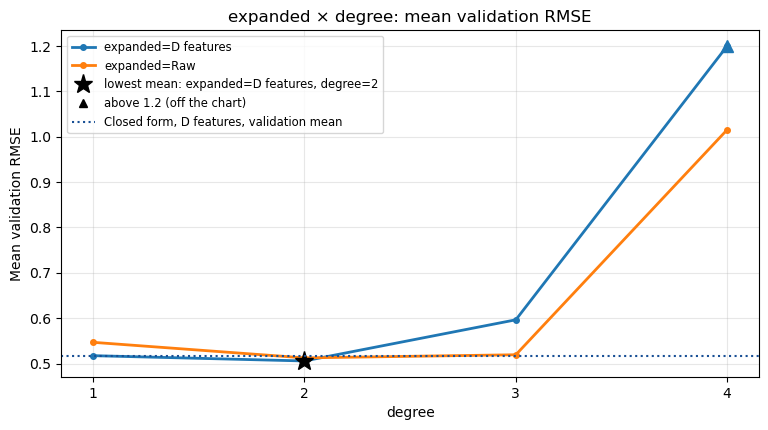

In [10]:
PLOTTING.parameter_cross(
	runs={pair: RUNS[name] for pair, name in PAIRS.items()},
	lines='expanded',
	x='degree',
	reference=('Closed form, D features', RUNS['Closed form, D features']),
	ymax=YMAX,
);

### Notes / Observations

- Degree 2 is the only gain: on D's features it beats D's model by -0.0117 (SE 0.0041). Squares and products of the 8 columns catch bends the straight lines miss.
- From degree 3 the model overfits: training RMSE keeps falling (0.4900 at degree 2 to 0.4359 at degree 3 on D's features) while validation RMSE rises, and at degree 4 both sets are worse than D's model.
- `D features, degree 3` reads within noise only because a few folds blow up, which makes its SE (0.0911) larger than its change.
- The polynomial does not replace D's shapes: on the raw attributes, degree 2 only ties D's model (-0.0049, SE 0.0050).
- D's features break down sooner than the raw attributes at degree 3 (0.5966 against 0.5195), so D's shapes and degree 3 do not go together.
- `D features, degree 1` is D's model itself, so its row ties at a change of 0.0000 by definition.

## Carried Degree

The Degree rule (see Method): of the pairs at degree 2 or above, the lowest mean among the candidates against D's model, or the lowest mean of them all when none is a candidate.

,carried
expanded,D features
degree,2


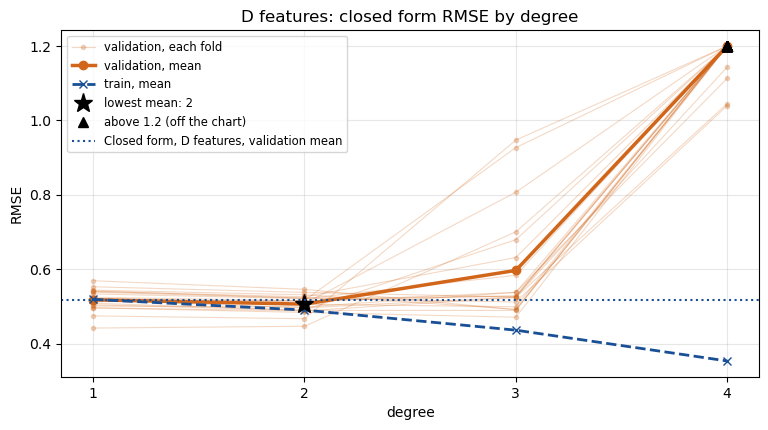

In [11]:
def carried_degree(pairs):
	"""The Degree rule: of the pairs at degree 2 or above, the one with the lowest mean among the candidates against
	D's model, or the lowest mean of them all when none is a candidate (the homework asks for polynomial regression)."""
	polynomial = {pair: name for pair, name in pairs.items() if pair[1] > 1}
	candidates = [
		pair for pair, name in polynomial.items()
		if STATISTICS.fold_difference(baseline=RUNS['Closed form, D features'], candidate=RUNS[name], folds=FOLDS).verdict == 'candidate'
	]
	return min(candidates or polynomial, key=lambda pair: RUNS[polynomial[pair]]['validation rmse'].mean())

EXPANDED, DEGREE = carried_degree(PAIRS)
STARTING_SHAPES, EXPAND = SETS[EXPANDED]
CARRIED = PAIRS[(EXPANDED, DEGREE)]
display(pd.Series({'expanded': EXPANDED, 'degree': DEGREE}, dtype=object).to_frame('carried'))

PLOTTING.parameter_search(
	runs={degree: RUNS[PAIRS[(EXPANDED, degree)]] for degree in DEGREES},
	parameter='degree',
	reference=('Closed form, D features', RUNS['Closed form, D features']),
	ymax=YMAX,
	title=f'{EXPANDED}: closed form RMSE by degree',
);

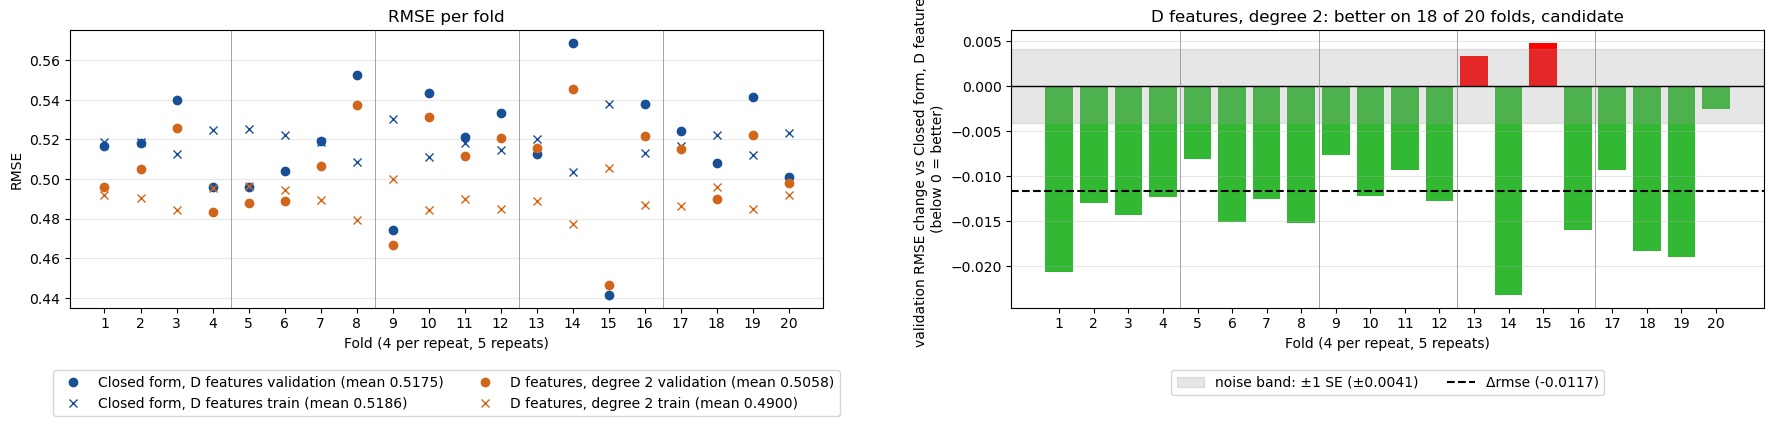

In [12]:
compare('Closed form, D features', CARRIED)

### Notes / Observations

- Carried: D's features with every column expanded, at degree 2. It is a candidate, so the forced part of the Degree rule is not needed.
- The curve has the textbook shape: degree 1 is a little too simple, degree 2 is the low point, and from degree 3 the folds scatter (the highest at 0.9471 in Closed Form on Polynomial Columns) while training RMSE keeps falling.
- The gain is broad: only folds 13 and 15 get worse, both by less than 0.005.
- Degree 2 opens a small gap that degree 1 did not have: training RMSE 0.4900 against 0.5058 on validation. This is the gap a penalty can act on in Regularization.

# Missing Values

The degree search fills a missing value with its attribute's median. Each row below handles the 185 incomplete training rows another way, on the raw attributes at the carried degree, against the median (`Raw, degree 2`). As in D, this runs before the shapes:
- **Drop incomplete rows:** train on the complete rows only.
- **Mean:** fill with the attribute's mean.
- **KNN:** fill with the mean of the 5 most similar rows, measured on standardized attributes.
- **KNN, in the attributes' units:** KNN's fill turned back into each attribute's own units (`ScaledKNNImputer`), so a shape can use it.
- **Iterative:** predict each missing value from the other attributes, in rounds.
- **+ missing flags:** each imputer again, plus a 0/1 column per attribute marking the filled rows.

In [13]:
def raw_closed_form(imputer):
	"""The closed form on the raw attributes at the carried degree, with this imputer."""
	return build(PIPELINES.SVDRegression(), RAW, imputer=imputer, degree=DEGREE)

score('Drop incomplete rows', raw_closed_form(None), folds=DROP_FOLDS)
score('Mean', raw_closed_form(SimpleImputer(strategy='mean')))
score('Mean + missing flags', raw_closed_form(SimpleImputer(strategy='mean', add_indicator=True)))
score('Median + missing flags', raw_closed_form(SimpleImputer(strategy='median', add_indicator=True)))
score('KNN', raw_closed_form(make_pipeline(StandardScaler(), KNNImputer())))
score("KNN, in the attributes' units", raw_closed_form(ScaledKNNImputer()))
score('KNN + missing flags', raw_closed_form(make_pipeline(StandardScaler(), KNNImputer(add_indicator=True))))
score('Iterative', raw_closed_form(IterativeImputer(random_state=SEED)))
score('Iterative + missing flags', raw_closed_form(IterativeImputer(random_state=SEED, add_indicator=True)))

MISSING = [
	'Drop incomplete rows',
	'Mean', 'Mean + missing flags',
	'Median + missing flags',
	'KNN', "KNN, in the attributes' units", 'KNN + missing flags',
	'Iterative', 'Iterative + missing flags',
]
table(MISSING, baseline=PAIRS[('Raw', DEGREE)])

,rmse,train rmse,Δrmse,SE,better folds,verdict
"Raw, degree 2",0.5126,0.4939,NaN,NaN,,baseline
Drop incomplete rows,0.5113,0.4856,-0.0013,0.0043,14 of 20,within noise
Mean,0.5125,0.4939,-0.0001,0.0004,11 of 20,within noise
Mean + missing flags,0.5101,0.4668,-0.0025,0.0031,13 of 20,within noise
Median + missing flags,0.5101,0.4668,-0.0025,0.0031,13 of 20,within noise
KNN,0.5105,0.4947,-0.0021,0.0014,16 of 20,candidate
"KNN, in the attributes' units",0.5105,0.4947,-0.0021,0.0014,16 of 20,candidate
KNN + missing flags,0.5099,0.4645,-0.0028,0.0031,14 of 20,within noise
Iterative,0.5116,0.4977,-0.0010,0.0015,12 of 20,within noise
Iterative + missing flags,0.5104,0.4655,-0.0023,0.0032,13 of 20,within noise


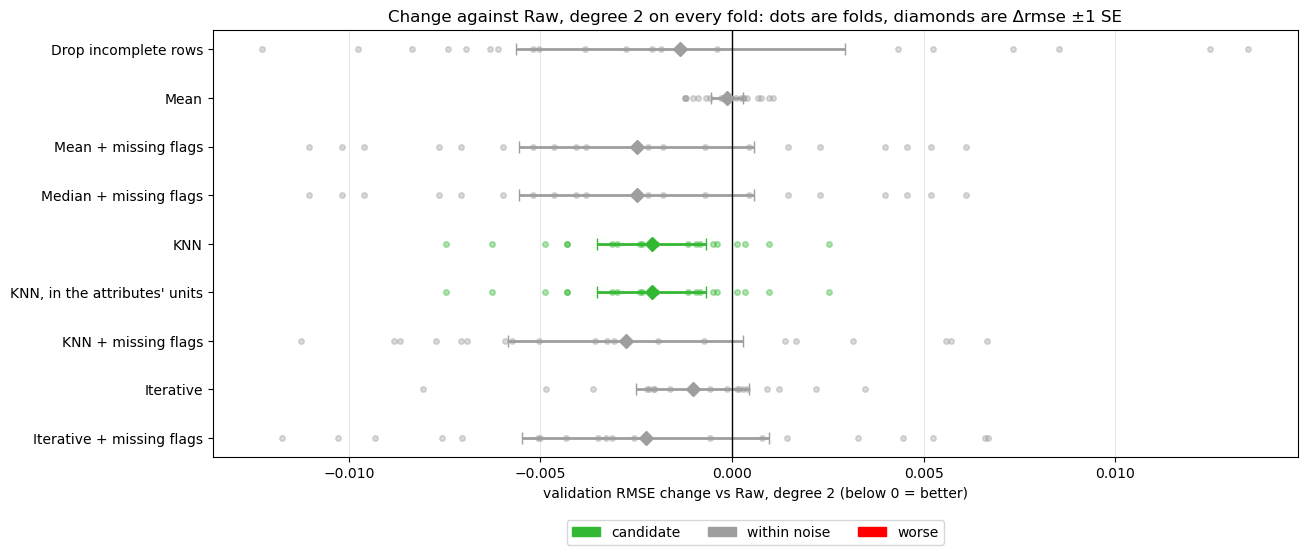

In [14]:
deltas(MISSING, baseline=PAIRS[('Raw', DEGREE)])

### Notes / Observations

- KNN is the only imputer that beats the median at degree 2: -0.0021 (SE 0.0014). It is carried into the shapes.
- `KNN, in the attributes' units` gives KNN's numbers exactly: turning the fill back into the attributes' units changes nothing but the units, so the shapes can use it.
- Missing flags only help on training rows: with flags, training RMSE falls to 0.4645 to 0.4668, below every imputer without them, while no flag row clears 1 SE on validation.
- With flags, mean and median give the same model: the flag's coefficient absorbs whichever value fills the row.

# Feature Shapes

The start is the carried pair, D's features with every column expanded at degree 2, now with the carried imputer: KNN, a candidate against the median, in the attributes' own units. Each experiment changes one thing against the start, from the options D tested for that attribute: back to raw, another of its shapes, a shape added to a raw attribute, a dropped attribute back in, or the attribute dropped.

| Attribute | In the start | Tested against it |
|---|---|---|
| `Social support` | reciprocal, 1 / (1.2 - x) | raw, hinge |
| `Healthy life expectancy at birth` | floor | raw, hinge, dropped |
| `Generosity` | hinge | raw, high generosity flag, dropped |
| `Freedom to make life choices` | raw | hinge, reciprocal |
| `Log GDP per capita` | raw | hinge |
| `Negative affect` | dropped | back raw, back with its hinge |
| `Perceptions of corruption`, `Positive affect` | raw | nothing: Q1B found no shape worth testing |

Every model in this section is the closed form at degree 2, with every column expanded and the KNN imputer.

## Start

In [15]:
IMPUTER = ScaledKNNImputer()  # KNN is a candidate against the median: the same fill, in the attributes' own units, which the shapes need

def closed_form(shapes):
	"""The closed form of shapes at the carried degree, expanded columns and imputer."""
	return build(PIPELINES.SVDRegression(), shapes, imputer=IMPUTER, degree=DEGREE, expand=EXPAND)

score('Start', closed_form(STARTING_SHAPES))

table(['Start'], baseline=CARRIED)

,rmse,train rmse,Δrmse,SE,better folds,verdict
"D features, degree 2",0.5058,0.4900,NaN,NaN,,baseline
Start,0.5037,0.4903,-0.0021,0.0022,13 of 20,within noise


### Notes / Observations

- KNN with D's shapes is within noise of the median (-0.0021, SE 0.0022). It stays as the start because it won the imputer tier; Missing Recheck tests it again on the carried set.

## Experiments

Each row changes one thing against `Start`.

In [16]:
EXPERIMENTS = {
	'Raw: Social': {**STARTING_SHAPES, SOCIAL: 'passthrough'},
	'Raw: Life exp': {**STARTING_SHAPES, LIFE_EXP: 'passthrough'},
	'Raw: Generosity': {**STARTING_SHAPES, GENEROSITY: 'passthrough'},
	'Swap: Social hinge': {**STARTING_SHAPES, SOCIAL: shape(SOCIAL, 'hinge')},
	'Swap: Life exp hinge': {**STARTING_SHAPES, LIFE_EXP: shape(LIFE_EXP, 'hinge')},
	'Swap: Generosity flag': {**STARTING_SHAPES, GENEROSITY: shape(GENEROSITY, 'step')},
	'Add: Freedom hinge': {**STARTING_SHAPES, FREEDOM: shape(FREEDOM, 'hinge')},
	'Add: Freedom reciprocal': {**STARTING_SHAPES, FREEDOM: shape(FREEDOM, 'reciprocal')},
	'Add: GDP hinge': {**STARTING_SHAPES, GDP: shape(GDP, 'hinge')},
	'Back: Neg affect': {**STARTING_SHAPES, NEG_AFFECT: 'passthrough'},
	'Back: Neg affect hinge': {**STARTING_SHAPES, NEG_AFFECT: shape(NEG_AFFECT, 'hinge')},
	'Drop: Generosity': {**STARTING_SHAPES, GENEROSITY: 'drop'},
	'Drop: Life exp': {**STARTING_SHAPES, LIFE_EXP: 'drop'},
}
for name, shapes in EXPERIMENTS.items():
	score(name, closed_form(shapes))

table(list(EXPERIMENTS), baseline='Start')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Start,0.5037,0.4903,NaN,NaN,,baseline
Raw: Social,0.5058,0.4924,0.0021,0.0026,5 of 20,within noise
Raw: Life exp,0.5110,0.4964,0.0073,0.0024,1 of 20,worse
Raw: Generosity,0.5016,0.4921,-0.0021,0.0015,16 of 20,candidate
Swap: Social hinge,0.5050,0.4859,0.0013,0.0025,7 of 20,within noise
Swap: Life exp hinge,0.5033,0.4863,-0.0004,0.0029,11 of 20,within noise
Swap: Generosity flag,0.5038,0.4939,0.0001,0.0024,10 of 20,within noise
Add: Freedom hinge,0.5029,0.4870,-0.0008,0.0022,12 of 20,within noise
Add: Freedom reciprocal,0.5025,0.4905,-0.0012,0.0012,13 of 20,within noise
Add: GDP hinge,0.5004,0.4850,-0.0033,0.0021,16 of 20,candidate


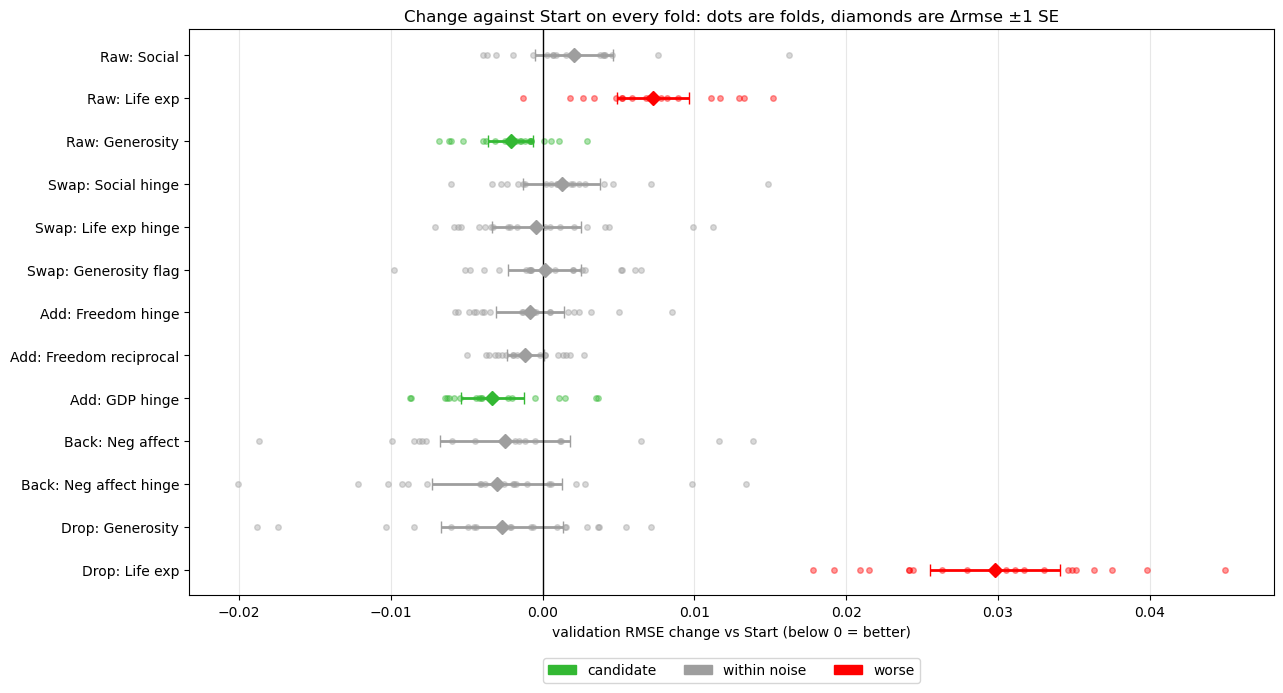

In [17]:
deltas(list(EXPERIMENTS), baseline='Start')

### Notes / Observations

- Adding a hinge on `Log GDP per capita` is a candidate (-0.0033, SE 0.0021).
- `Generosity` does better raw than with its hinge: a candidate (-0.0021, SE 0.0015).
- `Social support` back to raw does slightly worse on most folds but is within noise (+0.0021, SE 0.0026), so by the carry rule the simpler raw column is carried.
- `Healthy life expectancy at birth` still needs its floor: back to raw is worse (+0.0073), and dropping it costs even more.
- Putting `Negative affect` back fits the training rows more than the validation rows (training RMSE 0.4761 with its hinge) and is within noise, so it stays out.

## Combined

Every candidate, plus every change back to raw that is within noise (it makes the model simpler), together. A drop that is only within noise is left to Drop One, which removes one attribute at a time, so two attributes that cover for each other cannot leave together. When several rows touch the same attribute, the one with the lowest rmse wins. If Combined has a higher mean than `Start`, the best single change is carried instead.

In [18]:
COMBINED = {
	**STARTING_SHAPES,
	SOCIAL: 'passthrough',  # back to raw: within noise, and simpler than its reciprocal
	GENEROSITY: 'passthrough',  # candidate; dropping it is only within noise, so it is left to Drop One
	GDP: shape(GDP, 'hinge'),  # candidate
}
score('Combined', closed_form(COMBINED))

table(['Combined'], baseline='Start')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Start,0.5037,0.4903,NaN,NaN,,baseline
Combined,0.4976,0.4883,-0.0061,0.0023,19 of 20,candidate


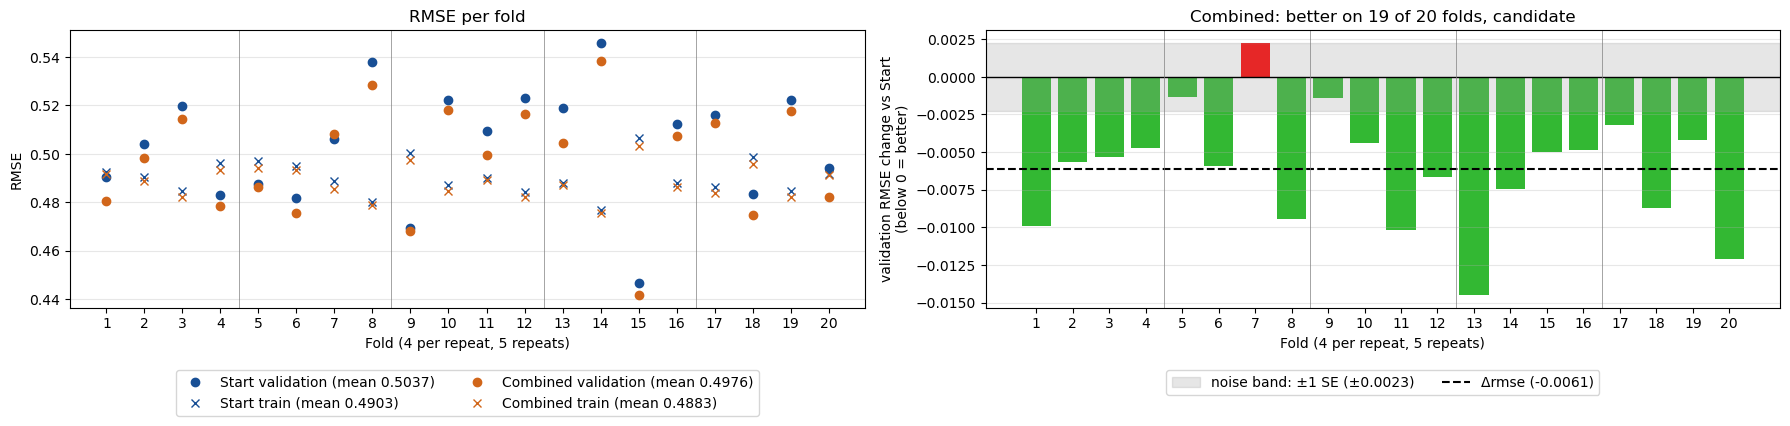

In [19]:
compare('Start', 'Combined')

### Notes / Observations

- The three changes add up: Combined beats the start by -0.0061 (SE 0.0023), more than the hinge on `Log GDP per capita` alone.
- The gain is on new rows: training RMSE barely moves (0.4903 to 0.4883).

# Drop One

Every attribute left in the model has to earn its place: dropping it must raise the mean validation RMSE. Each round drops every remaining attribute one at a time. When some drops do not raise the mean, the cheapest of them (the lowest rmse once dropped) first gets its other Q1B shapes, and one that beats the drop on the mean earns the attribute its place. Otherwise the attribute is dropped and the next round starts from the smaller model, so two attributes that cover for each other cannot leave together. The rounds end when every drop raises the mean.

The mean is used here, not the 1 SE rule: the 1 SE rule asks whether a change is real, while Drop One only asks whether the model is better with the attribute or without it. With few folds, the SE can be too wide to confirm a cost the model really pays, and the rounds would strip attributes it needs.

In [20]:
def drop_one(shapes, prefix):
	"""Score the closed form of shapes with each attribute still in it dropped, one at a time, and return the run names."""
	names = []
	for attribute in ATTRIBUTES:
		if shapes.get(attribute) != 'drop':
			name = f'{prefix}: drop {Q1_CONSTS.SHORT_NAMES[attribute]}'
			score(name, closed_form({**shapes, attribute: 'drop'}))
			names.append(name)
	return names

## Round 1

In [21]:
ROUND_1 = drop_one(COMBINED, 'Round 1')

table(ROUND_1, baseline='Combined')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Combined,0.4976,0.4883,NaN,NaN,,baseline
Round 1: drop GDP,0.5209,0.5211,0.0233,0.0040,0 of 20,worse
Round 1: drop Social,0.5164,0.5132,0.0189,0.0041,0 of 20,worse
Round 1: drop Life exp,0.5270,0.5145,0.0294,0.0046,0 of 20,worse
Round 1: drop Freedom,0.4994,0.4945,0.0018,0.0018,6 of 20,worse
Round 1: drop Generosity,0.4970,0.4935,-0.0005,0.0028,12 of 20,within noise
Round 1: drop Corruption,0.5007,0.4926,0.0032,0.0014,2 of 20,worse
Round 1: drop Pos affect,0.5237,0.5188,0.0261,0.0052,0 of 20,worse


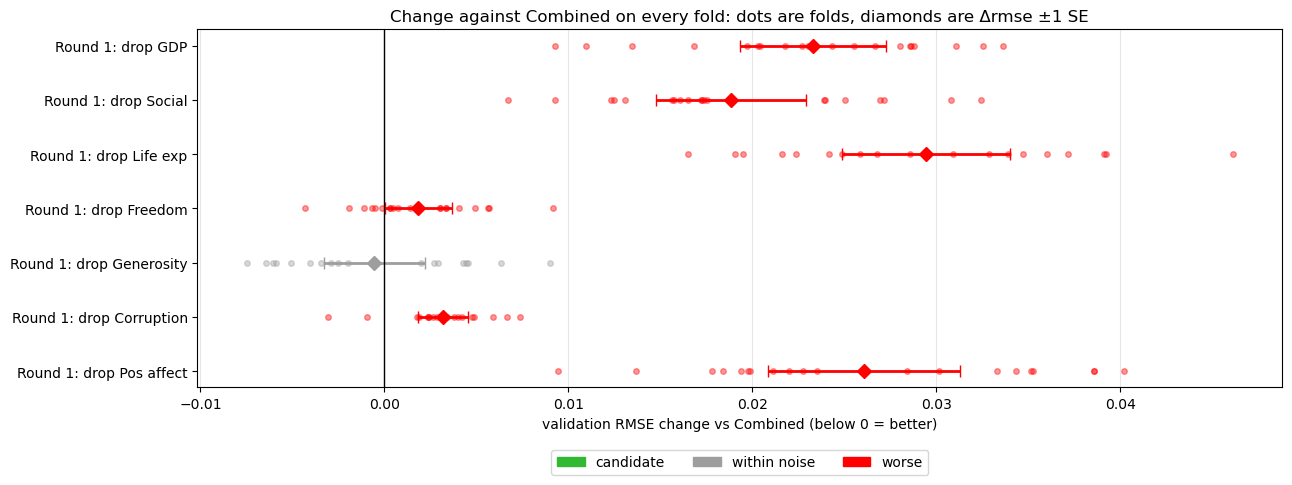

In [22]:
deltas(ROUND_1, baseline='Combined')

### Notes / Observations

- Only `Generosity` might go: dropping it lowers the mean slightly (-0.0005, SE 0.0028), while every other drop raises it.
- `Freedom to make life choices` is the closest call kept: dropping it costs +0.0018 (SE 0.0018).

### Generosity

Dropping `Generosity` is the only drop that does not raise the mean validation RMSE. Its other Q1B shapes, the hinge and the high generosity flag, get their chance first: one that beats the drop on the mean keeps the attribute in the model.

In [23]:
score('Round 1: Generosity hinge', closed_form({**COMBINED, GENEROSITY: shape(GENEROSITY, 'hinge')}))
score('Round 1: Generosity flag', closed_form({**COMBINED, GENEROSITY: shape(GENEROSITY, 'step')}))

table(['Round 1: Generosity hinge', 'Round 1: Generosity flag'], baseline='Round 1: drop Generosity')

,rmse,train rmse,Δrmse,SE,better folds,verdict
Round 1: drop Generosity,0.4970,0.4935,NaN,NaN,,baseline
Round 1: Generosity hinge,0.5019,0.4867,0.0049,0.0035,5 of 20,worse
Round 1: Generosity flag,0.5001,0.4900,0.0031,0.0031,6 of 20,worse


### Notes / Observations

- Neither shape earns `Generosity` its place: the hinge and the flag both do worse than dropping it (the flag, the closer of the two, by +0.0031), so it is dropped. D kept a hinge on it; at degree 2 it adds nothing.

## Round 2

In [24]:
FEATURES = {**COMBINED, GENEROSITY: 'drop'}  # neither shape beats the drop, so Generosity is dropped
score('Closed form, features', closed_form(FEATURES))
ROUND_2 = drop_one(FEATURES, 'Round 2')

table(ROUND_2, baseline='Closed form, features')

,rmse,train rmse,Δrmse,SE,better folds,verdict
"Closed form, features",0.4970,0.4935,NaN,NaN,,baseline
Round 2: drop GDP,0.5181,0.5260,0.0211,0.0049,0 of 20,worse
Round 2: drop Social,0.5162,0.5193,0.0192,0.0039,0 of 20,worse
Round 2: drop Life exp,0.5315,0.5235,0.0345,0.0050,0 of 20,worse
Round 2: drop Freedom,0.4993,0.4995,0.0023,0.0019,4 of 20,worse
Round 2: drop Corruption,0.5007,0.4977,0.0037,0.0014,2 of 20,worse
Round 2: drop Pos affect,0.5257,0.5267,0.0287,0.0050,0 of 20,worse


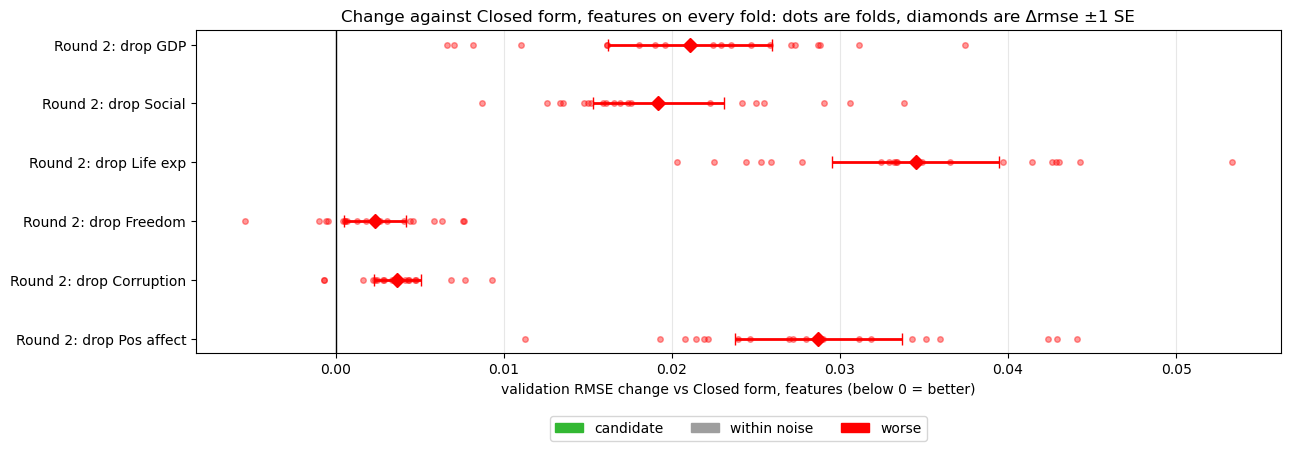

In [25]:
deltas(ROUND_2, baseline='Closed form, features')

### Notes / Observations

- The rounds end: every drop raises the mean. The closest call is again `Freedom to make life choices` (+0.0023, SE 0.0019).
- The carried feature set: 6 attributes, `Log GDP per capita` with a hinge, `Healthy life expectancy at birth` with its floor, the other 4 raw, every column expanded at degree 2. `Generosity` and `Negative affect` are out.

# Missing Recheck

The carried KNN against the median and against dropping the incomplete rows, on the carried feature set.

In [26]:
score('Features, median', build(PIPELINES.SVDRegression(), FEATURES, imputer=MEDIAN, degree=DEGREE, expand=EXPAND))
score('Features, drop incomplete rows', build(PIPELINES.SVDRegression(), FEATURES, imputer=None, degree=DEGREE, expand=EXPAND), folds=DROP_FOLDS)

table(['Features, median', 'Features, drop incomplete rows'], baseline='Closed form, features')

,rmse,train rmse,Δrmse,SE,better folds,verdict
"Closed form, features",0.4970,0.4935,NaN,NaN,,baseline
"Features, median",0.4962,0.4898,-0.0008,0.0022,13 of 20,within noise
"Features, drop incomplete rows",0.4943,0.4786,-0.0027,0.0024,12 of 20,candidate


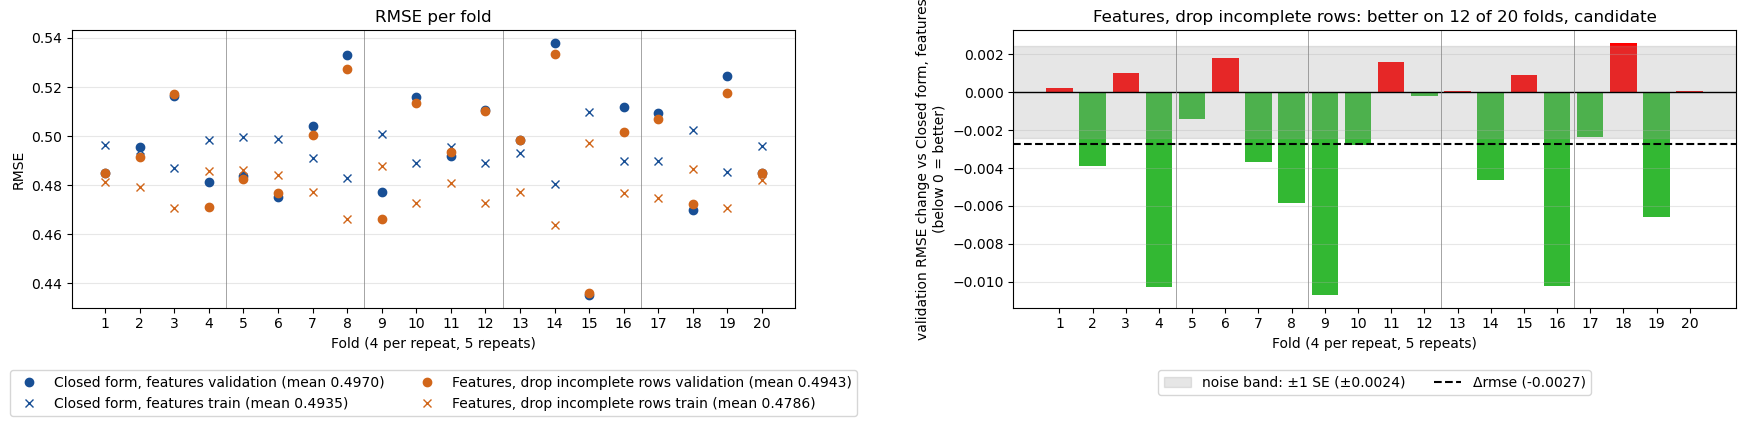

In [27]:
compare('Closed form, features', 'Features, drop incomplete rows')

### Notes / Observations

- Dropping the 185 incomplete rows beats KNN on the carried set (-0.0027, SE 0.0024), so every model from here on trains on the complete rows only. KNN shaped the ladder but is not in the final model.
- The gain rests on a few folds: most of it comes from folds 4, 9 and 16, while 6 folds are slightly worse.
- KNN's edge over the median is gone on the carried set: the median is within noise of it (-0.0008, SE 0.0022).

# Carried Feature Set

The feature set, degree and training rows every model from here on uses, against D's model.

In [28]:
IMPUTER, CV_FOLDS = None, DROP_FOLDS  # dropping the incomplete rows is a candidate: every model from here on trains on the complete rows only
CLOSED_FORM = 'Features, drop incomplete rows'  # the carried closed form, the one SGD is compared against

table([CLOSED_FORM], baseline='Closed form, D features')

,rmse,train rmse,Δrmse,SE,better folds,verdict
"Closed form, D features",0.5175,0.5186,NaN,NaN,,baseline
"Features, drop incomplete rows",0.4943,0.4786,-0.0232,0.0051,20 of 20,candidate


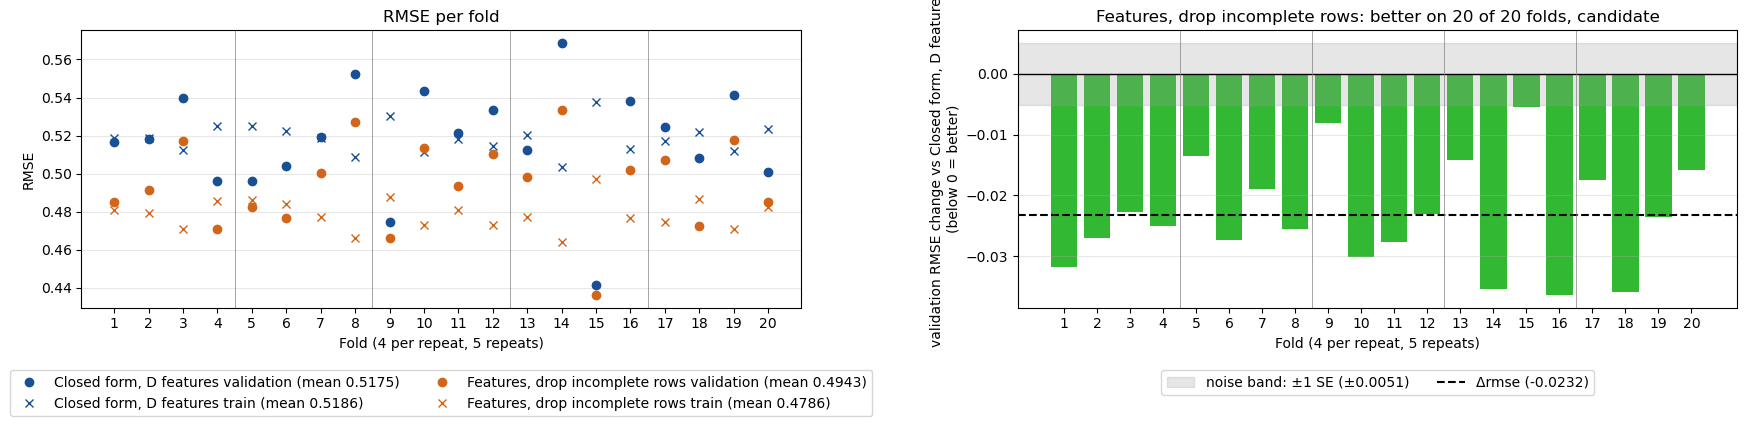

In [29]:
compare('Closed form, D features', CLOSED_FORM)

### Notes / Observations

- The carried model beats D's model on every fold (-0.0232, SE 0.0051): the polynomial at degree 2 is a real gain over D's straight lines.
- A training gap appears that D's model did not have: training RMSE 0.4786 against 0.4943 on validation, now that both are complete rows. This is the gap a penalty, or an earlier SGD stop, can act on.

# SGD

`SGDRegressor` on the carried feature set, at the carried degree. As in D, the search starts from scikit-learn's defaults. Every setting is written out, none left to a default: `penalty=None` (the default is a light L2 penalty), the learning rate schedule, `eta0`, `power_t`, `max_iter` and `tol`. `max_iter` is only a ceiling: a fit stops once its training loss improves by less than `tol` for 5 epochs in a row. Every model trains on the complete rows only (see Missing Recheck).

In [30]:
SGD_SETTINGS = dict(
	penalty=None,
	learning_rate='invscaling',  # step = eta0 / t ** power_t, shrinking as training goes on
	eta0=0.01,
	power_t=0.25,
	average=False,
	max_iter=MAX_ITER,
	tol=1e-3,
	random_state=SEED,
)
SETTINGS = {}  # the settings of every SGD run, keyed by name

def sgd(name, settings, degree=None):
	"""Cross validate SGD with these settings on the carried feature set, at degree (the carried degree when omitted),
	and keep the settings under name."""
	SETTINGS[name] = settings
	pipeline = build(SGDRegressor(**settings), FEATURES, imputer=IMPUTER, degree=DEGREE if degree is None else degree, expand=EXPAND)
	score(name, pipeline, folds=CV_FOLDS)

def sweep(parameter, values, settings, baseline, prefix='', log_x=False):
	"""Cross validate SGD at each value of one parameter, the others at settings, and show the table and the chart
	against baseline. Return the run names, keyed by value."""
	names = {value: f'{prefix}{parameter}={value}' for value in values}
	for value, name in names.items():
		sgd(name, {**settings, parameter: value})
	display(table(list(names.values()), baseline=baseline))
	PLOTTING.parameter_search(
		runs={value: RUNS[name] for value, name in names.items()},
		parameter=parameter,
		log_x=log_x,
		reference=(baseline, RUNS[baseline]),
		ymax=YMAX,
		title=f'{prefix}{parameter}: RMSE on every fold',
	)
	return names

def cross(first, first_values, second, second_values, settings, baseline=None, prefix='', log_x=False):
	"""Cross validate SGD at every pair of values of two parameters, the others at settings, and show the table and the
	chart against baseline (the run at the current pair when omitted). Return the run names, keyed by pair. log_x
	applies to second."""
	names = {(a, b): f'{prefix}{first}={a}, {second}={b}' for a in first_values for b in second_values}
	for (a, b), name in names.items():
		sgd(name, {**settings, first: a, second: b})
	if baseline is None:
		baseline = names[(settings[first], settings[second])]
	display(table([name for name in names.values() if name != baseline], baseline=baseline))
	PLOTTING.parameter_cross(
		runs={pair: RUNS[name] for pair, name in names.items()},
		lines=first,
		x=second,
		log_x=log_x,
		reference=None if baseline in names.values() else (baseline, RUNS[baseline]),
		ymax=YMAX,
	)
	return names

def carried(names, current):
	"""The carry rule: of the runs in names (keyed by value) that are candidates against the run at current, the value
	with the lowest mean, or current when none is."""
	candidates = [
		value for value, name in names.items()
		if STATISTICS.fold_difference(baseline=RUNS[names[current]], candidate=RUNS[name], folds=FOLDS).verdict == 'candidate'
	]
	return min(candidates, key=lambda value: RUNS[names[value]]['validation rmse'].mean(), default=current)

## SGD vs Closed Form

In [31]:
sgd('SGD', SGD_SETTINGS)

table(['SGD'], baseline=CLOSED_FORM)

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"Features, drop incomplete rows",0.4943,0.4786,NaN,NaN,,baseline,<NA>
SGD,0.4949,0.4839,0.0006,0.0029,8 of 20,within noise,17


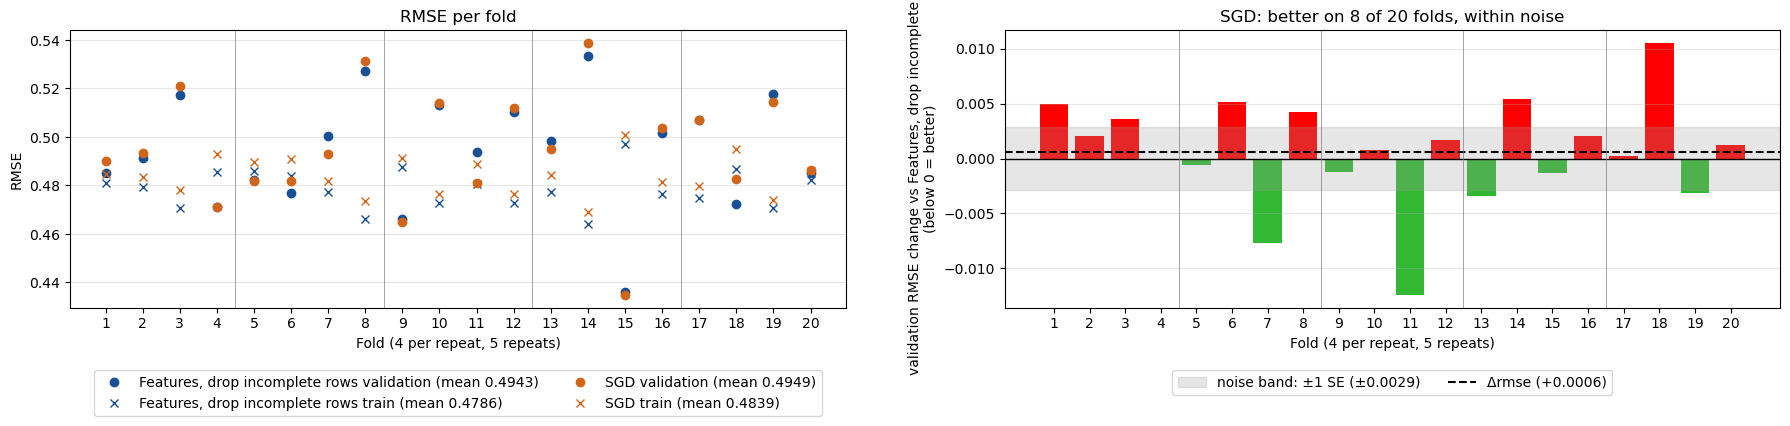

In [32]:
compare(CLOSED_FORM, 'SGD')

### Notes / Observations

- At scikit-learn's defaults, SGD finds the closed form's fit at degree 2: within noise (+0.0006, SE 0.0029).

## Hyperparameter Search

The degree is searched first, together with the starting step `eta0`, since a polynomial with more columns can need a smaller step. Then the learning rate schedule and `eta0` together at the carried degree, every pair of the 4 schedules and 6 steps, since a schedule only sets how the step changes from `eta0`. Then the stopping tolerance `tol`. Each table compares every value against the current settings (its baseline row), and a value replaces them only when it is a candidate. Of several candidates, the lowest mean wins.

### Degree × eta0

Degrees 1 to 4 with every starting step, the other settings at scikit-learn's defaults. A higher degree has more columns, and cubes and fourth powers of standardized columns have long tails, which can need a smaller step. SGD's early stop can also hide overfitting the closed form shows. As in Degree and Expanded Columns, only degrees 2 and above can be carried.

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"degree=2, eta0=0.01",0.4949,0.4839,NaN,NaN,,baseline,17
"degree=1, eta0=1e-05",0.9214,0.9209,0.4265,0.0219,0 of 20,worse,99
"degree=1, eta0=0.0001",0.5744,0.5733,0.0795,0.0072,0 of 20,worse,48
"degree=1, eta0=0.001",0.5341,0.5320,0.0392,0.0059,0 of 20,worse,11
"degree=1, eta0=0.01",0.5302,0.5264,0.0353,0.0053,0 of 20,worse,7
"degree=1, eta0=0.1",0.5396,0.5382,0.0447,0.0101,0 of 20,worse,17
"degree=1, eta0=1",0.6331,0.6226,0.1382,0.0412,0 of 20,worse,44
"degree=2, eta0=1e-05",0.8730,0.8712,0.3780,0.0188,0 of 20,worse,93
"degree=2, eta0=0.0001",0.5892,0.5845,0.0943,0.0108,0 of 20,worse,49
"degree=2, eta0=0.001",0.5073,0.4998,0.0124,0.0030,0 of 20,worse,16


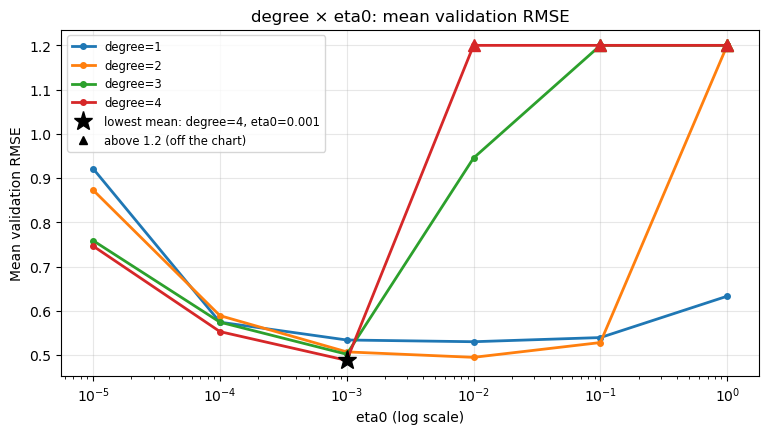

In [33]:
names = {(degree, eta0): f'degree={degree}, eta0={eta0}' for degree in DEGREES for eta0 in ETA0S}
for (degree, eta0), name in names.items():
	sgd(name, {**SGD_SETTINGS, 'eta0': eta0}, degree=degree)
baseline = names[(DEGREE, SGD_SETTINGS['eta0'])]
display(table([name for name in names.values() if name != baseline], baseline=baseline))
PLOTTING.parameter_cross(runs={pair: RUNS[name] for pair, name in names.items()}, lines='degree', x='eta0', log_x=True, ymax=YMAX)

polynomial = {pair: name for pair, name in names.items() if pair[0] > 1}  # degree 1 is not polynomial regression
DEGREE, eta0 = carried(polynomial, (DEGREE, SGD_SETTINGS['eta0']))
SGD_SETTINGS = {**SGD_SETTINGS, 'eta0': eta0}

### Notes / Observations

- Degree 4 is the only gain: at `eta0` 0.001 it beats degree 2 by -0.0068 (SE 0.0048). The degree moves to 4.
- SGD's stop works as a brake: at degree 4 it stops after at most 21 epochs, long before the least squares fit. The closed form at degree 4 overfits badly on D's features (2.7380 in Degree and Expanded Columns); SGD at the same degree does not.
- The step that works shrinks as the degree grows: `eta0` 1 diverges from degree 2 on, 0.1 from degree 3, and 0.01 at degree 4.
- `degree=3, eta0=0.01` reads within noise only because some folds blow up and its SE (1.0892) is larger than its change.
- Every degree 1 run is worse than the degree 2 baseline (its best is 0.5302), so SGD confirms the polynomial terms help.

### Learning Rate Schedule × eta0 (Starting Step Size)

At the carried degree. `optimal` sets its own step from `alpha` and ignores `eta0`, so its 6 rows are the same model.

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/sklearn/linear_model/_stochastic_gradient.py:1561: ConvergenceWarning: Maximum number of iteration reached be

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"learning_rate=invscaling, eta0=0.001",0.4881,0.4700,NaN,NaN,,baseline,21
"learning_rate=constant, eta0=1e-05",0.5421,0.5313,0.0540,0.0066,0 of 20,worse,38
"learning_rate=constant, eta0=0.0001",0.4882,0.4693,0.0001,0.0023,10 of 20,within noise,26
"learning_rate=constant, eta0=0.001",24351074935.9278,28992108080.8296,24351074935.4397,25388438344.9062,0 of 20,within noise,6
"learning_rate=constant, eta0=0.01",4114239662852.3945,3898715917625.9521,4114239662851.9072,1557021652116.3364,0 of 20,worse,11
"learning_rate=constant, eta0=0.1",37104501498633.8203,37201555585834.0781,37104501498633.3359,10140624764857.5234,0 of 20,worse,11
"learning_rate=constant, eta0=1",452402460975518.3750,410261735905800.3750,452402460975517.8750,148358167995741.8125,0 of 20,worse,15
"learning_rate=optimal, eta0=1e-05",74189444191638.2812,71160494809673.1562,74189444191637.7812,19038480367555.9766,0 of 20,worse,86
"learning_rate=optimal, eta0=0.0001",74189444191638.2812,71160494809673.1562,74189444191637.7812,19038480367555.9766,0 of 20,worse,86
"learning_rate=optimal, eta0=0.001",74189444191638.2812,71160494809673.1562,74189444191637.7812,19038480367555.9766,0 of 20,worse,86


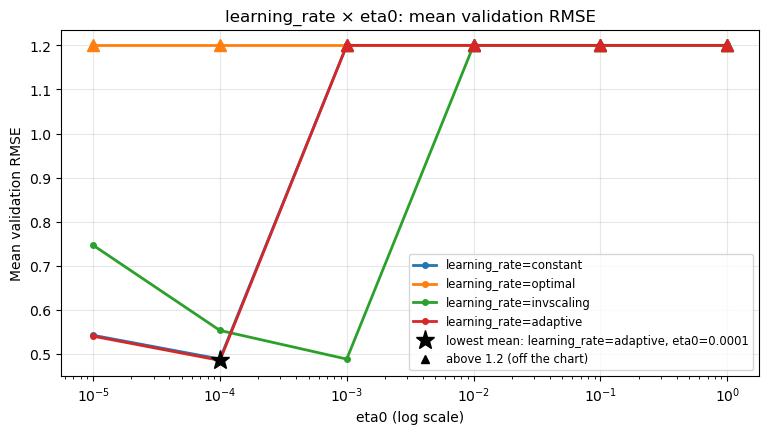

In [34]:
names = cross('learning_rate', LEARNING_RATE_SCHEDULES, 'eta0', ETA0S, SGD_SETTINGS, log_x=True)
learning_rate, eta0 = carried(names, (SGD_SETTINGS['learning_rate'], SGD_SETTINGS['eta0']))
SGD_SETTINGS = {**SGD_SETTINGS, 'learning_rate': learning_rate, 'eta0': eta0}

### Notes / Observations

- At degree 4 only `adaptive` at `eta0` 0.0001 is a candidate (-0.0029, SE 0.0025), and it is carried: a small step that is cut further whenever the training loss stalls.
- At degree 4 every schedule diverges from `eta0` 0.01 up, and at 0.001 only `invscaling` survives. `constant` and `adaptive` at 0.001 read within noise only because their SEs are as large as their changes; both are better on 0 of 20 folds.
- The ConvergenceWarnings above come from `adaptive` at 0.01 and 0.1: both diverge and run all 10,000 epochs. No run that converges reaches the limit.

### Stopping Tolerance (tol)

A fit stops once its training loss improves by less than `tol` for 5 epochs in a row, so a smaller `tol` trains longer. The loss is measured on the standardized target, so `tol` means the same in Q1 and Q2. This is the cross validated view of more epochs: if validation RMSE rises as `tol` shrinks, training longer overfits.

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
tol=0.001,0.4851,0.4662,NaN,NaN,,baseline,42
tol=0.01,0.4977,0.4830,0.0126,0.0024,0 of 20,worse,25
tol=0.0001,0.4770,0.4481,-0.0081,0.0037,18 of 20,candidate,105
tol=1e-05,0.4765,0.4433,-0.0086,0.0049,18 of 20,candidate,181
tol=1e-06,0.4763,0.4401,-0.0088,0.0055,17 of 20,candidate,1428


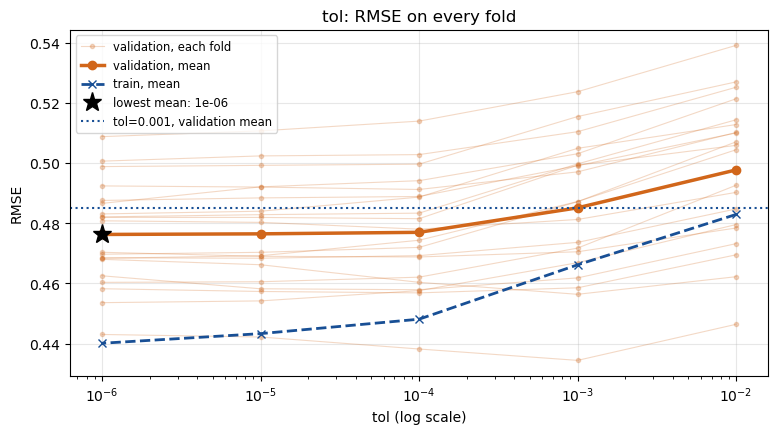

In [35]:
names = sweep('tol', TOLS, SGD_SETTINGS, baseline=f"tol={SGD_SETTINGS['tol']}", log_x=True)
SGD_SETTINGS = {**SGD_SETTINGS, 'tol': carried(names, SGD_SETTINGS['tol'])}

### Notes / Observations

- Training longer helps at degree 4: `tol` 0.0001 and below are all candidates, and 0.000001 has the lowest mean (0.4763), so it is carried.
- With it the slowest fold runs 1428 epochs.
- More epochs fit the training rows better without helping new rows any more: from `tol` 0.0001 on, validation RMSE is flat while training RMSE keeps falling (0.4481 to 0.4401). The gap widens, but validation RMSE does not rise, so these epochs do not overfit yet.
- `tol` 0.01 stops too early: worse by +0.0126.

## Tuned SGD vs Closed Form

In [36]:
sgd('SGD, tuned', SGD_SETTINGS)
display(pd.Series({**SGD_SETTINGS, 'degree': DEGREE}, name='carried').astype(str).to_frame())  # as text: the float format would round a small tol to 0

table(['SGD, tuned'], baseline=CLOSED_FORM)

,carried
penalty,None
learning_rate,adaptive
eta0,0.0001
power_t,0.25
average,False
max_iter,10000
tol,1e-06
random_state,42
degree,4


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"Features, drop incomplete rows",0.4943,0.4786,NaN,NaN,,baseline,<NA>
"SGD, tuned",0.4763,0.4401,-0.0180,0.0063,19 of 20,candidate,1428


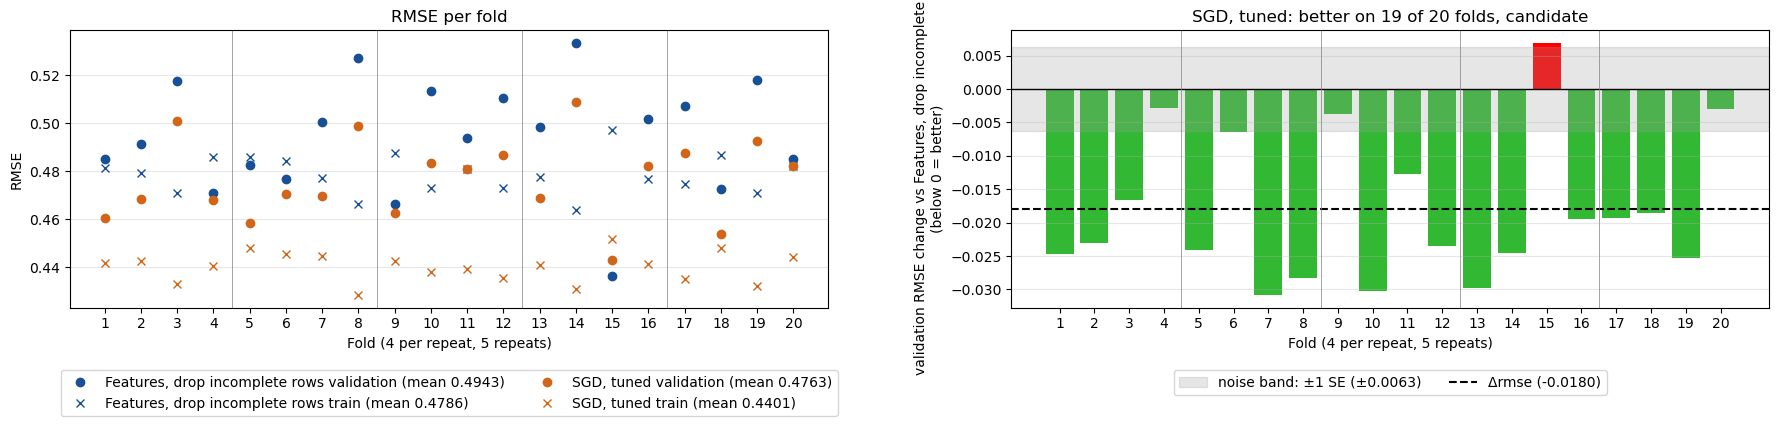

In [37]:
compare(CLOSED_FORM, 'SGD, tuned')

### Notes / Observations

- Tuned SGD at degree 4 beats the carried closed form at degree 2 (-0.0180, SE 0.0063): SGD's stop works as a brake the closed form does not have.
- The gap between training and validation grows: training RMSE 0.4401 against 0.4763 on validation. This is the gap a penalty can act on in Regularization.

# Regularization

The tuned SGD, at the carried degree, with a penalty: Ridge (`l2`), Lasso (`l1`) and Elastic Net (`elasticnet`, a mix of both), each against the tuned SGD with no penalty. `alpha`, the penalty's strength, is tried at 8 values from 0.000001 to 10. Elastic Net also has `l1_ratio`, its share of L1 in the penalty, so it is searched over every pair of `alpha` and `l1_ratio`, as scikit-learn's `ElasticNetCV` does. SGD's `alpha` is not the same scale as `Ridge`'s: for L2, `Ridge(alpha=n * a)` matches `SGDRegressor(alpha=a)` on n rows.

## Ridge and Lasso

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",0.4763,0.4401,NaN,NaN,,baseline,1428
"Ridge, alpha=1e-06",0.4763,0.4401,-0.0000,0.0000,13 of 20,within noise,1428
"Ridge, alpha=1e-05",0.4763,0.4401,-0.0000,0.0000,13 of 20,within noise,1428
"Ridge, alpha=0.0001",0.4763,0.4401,-0.0000,0.0000,13 of 20,within noise,1428
"Ridge, alpha=0.001",0.4763,0.4402,-0.0000,0.0000,13 of 20,within noise,1428
"Ridge, alpha=0.01",0.4759,0.4419,-0.0004,0.0007,10 of 20,within noise,1428
"Ridge, alpha=0.1",0.4780,0.4534,0.0016,0.0036,6 of 20,within noise,582
"Ridge, alpha=1",0.5188,0.5068,0.0425,0.0082,0 of 20,worse,85
"Ridge, alpha=10",0.6961,0.6904,0.2198,0.0135,0 of 20,worse,53


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",0.4763,0.4401,NaN,NaN,,baseline,1428
"Lasso, alpha=1e-06",0.4763,0.4402,0.0000,0.0001,10 of 20,within noise,1428
"Lasso, alpha=1e-05",0.4763,0.4402,-0.0000,0.0000,10 of 20,within noise,1428
"Lasso, alpha=0.0001",0.4761,0.4407,-0.0002,0.0005,9 of 20,within noise,1428
"Lasso, alpha=0.001",0.4759,0.4449,-0.0004,0.0017,10 of 20,within noise,1933
"Lasso, alpha=0.01",0.4873,0.4732,0.0110,0.0071,4 of 20,worse,234
"Lasso, alpha=0.1",0.5491,0.5442,0.0728,0.0090,0 of 20,worse,107
"Lasso, alpha=1",1.1279,1.1278,0.6516,0.0223,0 of 20,worse,27
"Lasso, alpha=10",1.1279,1.1278,0.6516,0.0223,0 of 20,worse,27


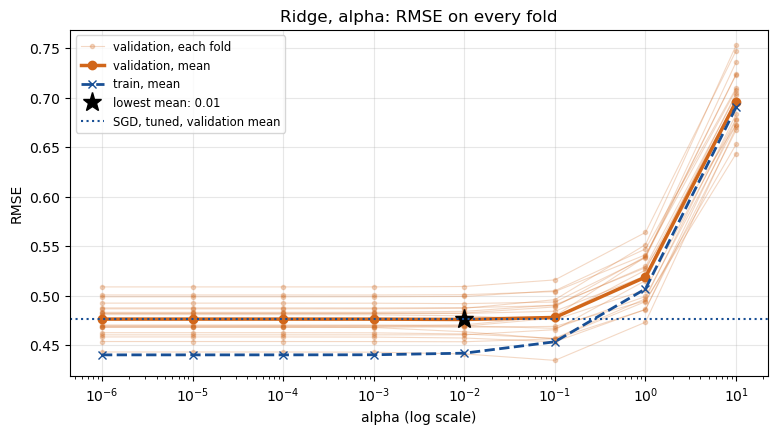

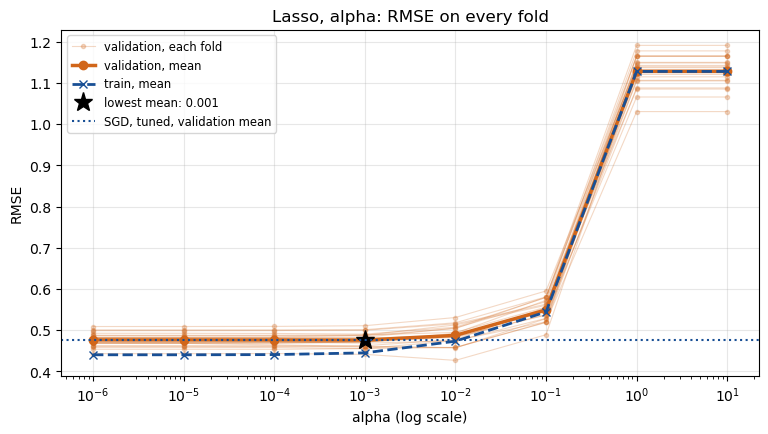

In [38]:
REGULARIZED = []  # every regularized run, the pool the selected model is picked from
for penalty, label in (('l2', 'Ridge'), ('l1', 'Lasso')):
	REGULARIZED += sweep('alpha', ALPHAS, {**SGD_SETTINGS, 'penalty': penalty}, baseline='SGD, tuned', prefix=f'{label}, ', log_x=True).values()

### Notes / Observations

- Small penalties change nothing: up to alpha 0.01 for Ridge and 0.001 for Lasso, every run is within noise of no penalty, and none lowers the mean by more than 0.0004.
- A penalty narrows the training gap without helping new rows: Ridge at alpha 0.01 raises training RMSE (0.4401 to 0.4419) while validation RMSE barely moves. The gap at degree 4 costs nothing on new rows, so there is no overfitting for a penalty to cure.
- L1 bites first: Lasso is worse from alpha 0.01 (+0.0110), Ridge only from alpha 1 (+0.0425).
- Strong penalties underfit: training and validation RMSE rise together (Ridge at alpha 10: 0.6904 and 0.6961).
- Lasso from alpha 1 predicts the mean: 1.1279, against Dummy's 1.1281.

## Elastic Net: l1_ratio × alpha

Every pair of the 6 `l1_ratio` values and the 8 `alpha` values. `l1_ratio` 0 would be Ridge and 1 would be Lasso.

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",0.4763,0.4401,NaN,NaN,,baseline,1428
"Elastic Net, l1_ratio=0.1, alpha=1e-06",0.4763,0.4401,-0.0000,0.0000,10 of 20,within noise,1428
"Elastic Net, l1_ratio=0.1, alpha=1e-05",0.4763,0.4402,0.0000,0.0001,10 of 20,within noise,1428
"Elastic Net, l1_ratio=0.1, alpha=0.0001",0.4763,0.4402,-0.0000,0.0000,10 of 20,within noise,1428
"Elastic Net, l1_ratio=0.1, alpha=0.001",0.4761,0.4409,-0.0002,0.0005,8 of 20,within noise,1428
"Elastic Net, l1_ratio=0.1, alpha=0.01",0.4758,0.4462,-0.0005,0.0021,8 of 20,within noise,1848
"Elastic Net, l1_ratio=0.1, alpha=0.1",0.4918,0.4786,0.0155,0.0074,2 of 20,worse,119
"Elastic Net, l1_ratio=0.1, alpha=1",0.6084,0.6038,0.1321,0.0113,0 of 20,worse,53
"Elastic Net, l1_ratio=0.1, alpha=10",1.1279,1.1278,0.6516,0.0223,0 of 20,worse,27
"Elastic Net, l1_ratio=0.15, alpha=1e-06",0.4763,0.4401,-0.0000,0.0000,10 of 20,within noise,1428


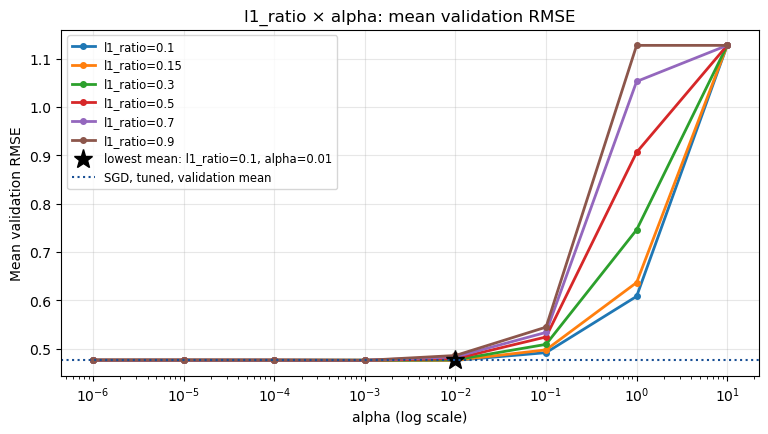

In [39]:
REGULARIZED += cross('l1_ratio', L1_RATIOS, 'alpha', ALPHAS, {**SGD_SETTINGS, 'penalty': 'elasticnet'}, baseline='SGD, tuned', prefix='Elastic Net, ', log_x=True).values()

### Notes / Observations

- Up to alpha 0.001 the mix barely matters: every pair is within noise of no penalty.
- At alpha 0.01 the mix starts to matter: `l1_ratio` 0.7 and 0.9 are worse, while 0.1 gives the lowest mean of all the regularized runs (0.4758).
- Once the penalty acts, more L1 costs more: at alpha 0.1 the cost grows from +0.0155 (`l1_ratio` 0.1) to +0.0683 (0.9), as in the Ridge and Lasso sweeps.
- Strong penalties reach the mean sooner with more L1: at alpha 1, `l1_ratio` 0.9 already predicts the mean (1.1279) while 0.1 is at 0.6084.

## Selected Model

The regularized setting with the lowest mean validation RMSE, against the tuned SGD with no penalty.

In [40]:
SELECTED = min(REGULARIZED, key=lambda name: RUNS[name]['validation rmse'].mean())
display(pd.Series({**SETTINGS[SELECTED], 'degree': DEGREE}, name=SELECTED).astype(str).to_frame())  # as text: the float format would round a small alpha or tol to 0

table([SELECTED], baseline='SGD, tuned')

,"Elastic Net, l1_ratio=0.1, alpha=0.01"
penalty,elasticnet
learning_rate,adaptive
eta0,0.0001
power_t,0.25
average,False
max_iter,10000
tol,1e-06
random_state,42
l1_ratio,0.1
alpha,0.01


,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"SGD, tuned",0.4763,0.4401,NaN,NaN,,baseline,1428
"Elastic Net, l1_ratio=0.1, alpha=0.01",0.4758,0.4462,-0.0005,0.0021,8 of 20,within noise,1848


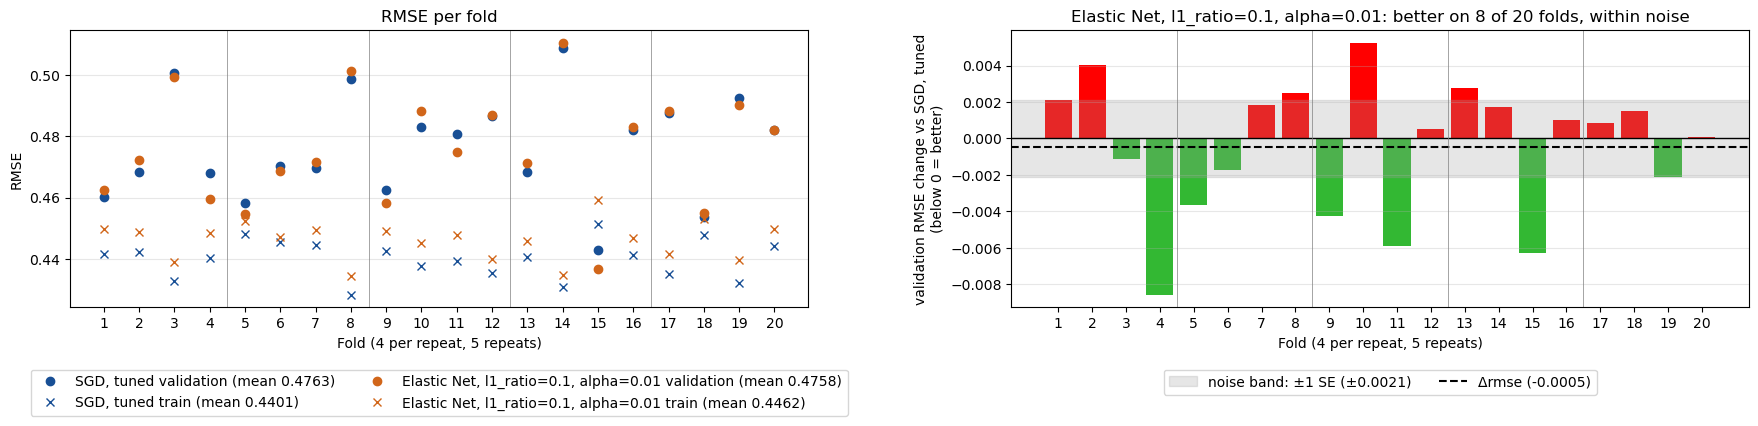

In [41]:
compare('SGD, tuned', SELECTED)

### Notes / Observations

- Selected as required, not because it helps: Elastic Net at `l1_ratio` 0.1 and alpha 0.01 has the lowest mean, within noise of no penalty (-0.0005, SE 0.0021).
- `l1_ratio` 0.9 at alpha 0.001 is level with it to 4 decimals (0.4758).
- It trades training fit for nothing on new rows: training RMSE rises to 0.4462 (0.4401 without the penalty) while validation RMSE stays level.

## Train on the Entire Training Set

The selected model refit on the 1,374 complete training rows (the incomplete rows are dropped, as in every fold since Missing Recheck) and saved. The saved pipeline takes the 8 raw attributes and builds its own columns, at degree 4. The test file has no missing values, so the saved model needs no imputer.

In [42]:
X_full, y_full = X.iloc[complete], y.iloc[complete]  # the complete rows: the incomplete rows are dropped, as in every fold
final = build(SGDRegressor(**SETTINGS[SELECTED]), FEATURES, imputer=IMPUTER, degree=DEGREE, expand=EXPAND).fit(X_full, y_full)
Q1_CONSTS.MODEL_OUTPUT_DIR.mkdir(exist_ok=True)
joblib.dump(final, Q1_CONSTS.MODEL_OUTPUT_DIR / 'polynomial_regression.joblib')

pd.Series({
	'training rows': len(X_full),
	'epochs run': PIPELINES.final_model(final).n_iter_,
	'train rmse': mean_squared_error(y_full, final.predict(X_full), squared=False),
}, dtype=object).to_frame(SELECTED)  # object: keeps the counts whole numbers

,"Elastic Net, l1_ratio=0.1, alpha=0.01"
training rows,1374
epochs run,245
train rmse,0.4506


### Notes / Observations

- The full fit matches cross validation: on the 1,374 complete rows it reaches a training RMSE of 0.4506, against 0.4462 averaged over the folds.
- It stops far sooner than the slowest fold (245 epochs against 1848): when `tol` ends a fit varies a lot from one set of rows to another.

## Training and Validation Loss by Epoch

The hint's `warm_start` loop restarts the learning rate schedule on every `fit` call, so epoch k here is a fresh fit with `max_iter=k` and the same seed, exactly the selected model's first k epochs. Once a fold's fit stops on its own (`tol`), its line stays flat. Shown on the 4 folds of the first cut. Epoch k costs a fresh fit of k epochs, so the epochs are scored on up to 60 points spread evenly on a log scale (rounding to whole epochs merges some of the first ones), up to 10 past the last fold's stop, and drawn on a log scale.

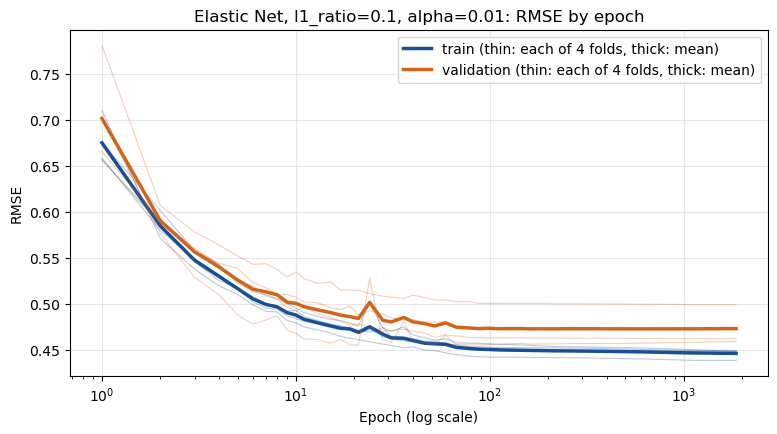

In [43]:
EPOCHS = int(RUNS[SELECTED]['epochs'].max()) + 10  # past the last fold's stop, where every line is flat
EPOCH_GRID = np.unique(np.round(np.geomspace(1, EPOCHS, 60)).astype(int))  # 60 points, evenly spread on a log scale
curve = PIPELINES.epoch_rmse(pipeline=build(SGDRegressor(**SETTINGS[SELECTED]), FEATURES, imputer=IMPUTER, degree=DEGREE, expand=EXPAND), X=X, y=y, folds=CV_FOLDS[:CV_SPLITS], epochs=EPOCH_GRID)
PLOTTING.loss_curve(curve=curve, title=f'{SELECTED}: RMSE by epoch', log_x=True, ymax=YMAX);

### Notes / Observations

- Learns fast, then holds: most of the drop comes in the first 10 epochs, and validation RMSE is flat from about epoch 100 to the end.
- No overfitting with more epochs: validation RMSE never turns back up, and the two lines stay about the same distance apart from the first epoch to the last.
- The small bump around epoch 24 comes from one fold, which settles again within a few epochs.

# Overfitting and Underfitting

Validation loss is read three ways in this notebook: by degree (Degree and Expanded Columns with the closed form, Degree × eta0 with SGD), by penalty (Regularization), and by epoch (Stopping Tolerance, and the loss curve above). This section puts the degrees side by side with the selected settings: cross validated on every fold, then loss by epoch at each degree. Overfitting and underfitting are read as in Method.

## By Degree

In [44]:
BY_DEGREE = [f'Selected settings, degree {degree}' for degree in DEGREES]
for degree, name in zip(DEGREES, BY_DEGREE):
	sgd(name, SETTINGS[SELECTED], degree=degree)

table(['Dummy', *BY_DEGREE], baseline=SELECTED)

,rmse,train rmse,Δrmse,SE,better folds,verdict,most epochs
"Elastic Net, l1_ratio=0.1, alpha=0.01",0.4758,0.4462,NaN,NaN,,baseline,1848
Dummy,1.1281,1.1085,0.6522,0.0225,0 of 20,worse,<NA>
"Selected settings, degree 1",0.5302,0.5262,0.0544,0.0083,0 of 20,worse,162
"Selected settings, degree 2",0.4948,0.4823,0.0190,0.0051,1 of 20,worse,529
"Selected settings, degree 3",0.4850,0.4621,0.0092,0.0026,1 of 20,worse,909
"Selected settings, degree 4",0.4758,0.4462,0.0000,0.0000,0 of 20,within noise,1848


### Notes / Observations

- A more flexible model keeps helping: validation RMSE falls at every degree (0.5302 at degree 1 to 0.4758 at degree 4), and every lower degree is worse by more than 1 SE.
- Degree 1 underfits: training and validation RMSE are both high and almost level (0.5262 and 0.5302).
- The gap grows with the degree without validation RMSE rising: at degree 4, training RMSE is 0.4462 against 0.4758. The closed form at degree 4 overfits on D's features (Degree and Expanded Columns); SGD's stop avoids it.
- Higher degrees need longer to settle: from at most 162 epochs at degree 1 to 1848 at degree 4.
- `Selected settings, degree 4` is the selected model itself, so its change is 0.0000 by definition.

## Loss by Epoch at Each Degree

The selected settings at degrees 1 to 4, on the same folds and epochs as the selected model's curve.

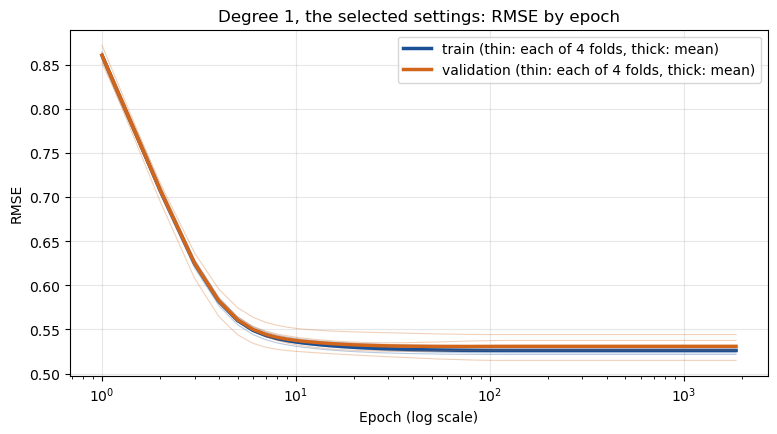

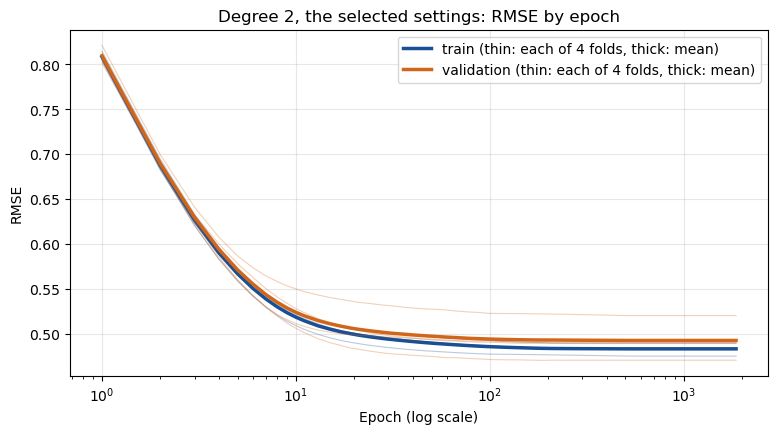

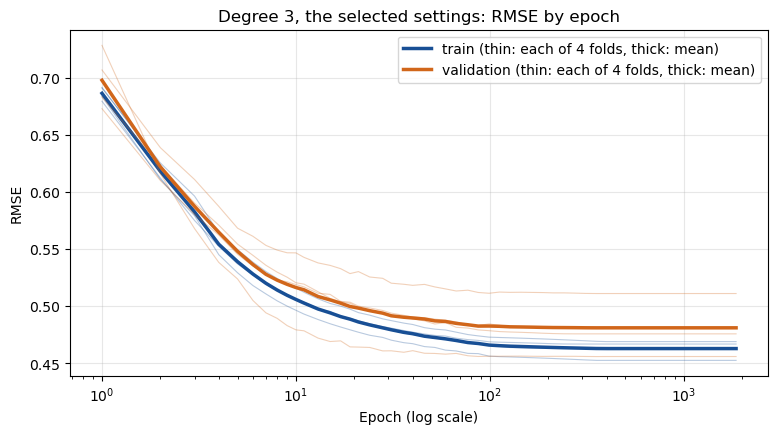

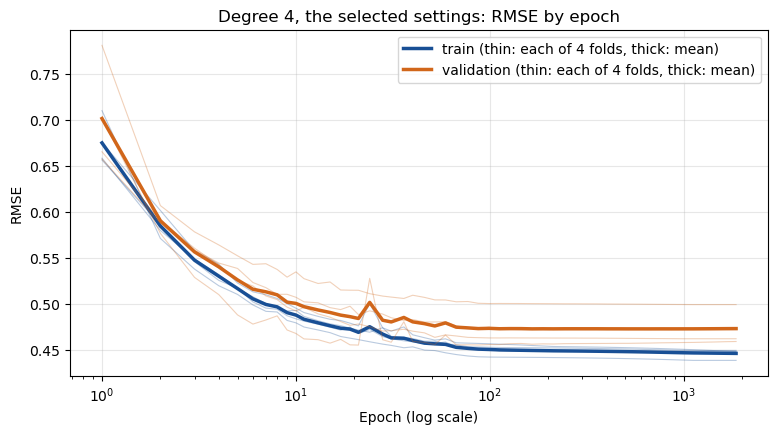

In [45]:
for degree in DEGREES:
	curve = PIPELINES.epoch_rmse(pipeline=build(SGDRegressor(**SETTINGS[SELECTED]), FEATURES, imputer=IMPUTER, degree=degree, expand=EXPAND), X=X, y=y, folds=CV_FOLDS[:CV_SPLITS], epochs=EPOCH_GRID)
	PLOTTING.loss_curve(curve=curve, title=f'Degree {degree}, the selected settings: RMSE by epoch', log_x=True, ymax=YMAX)

### Notes / Observations

- No degree overfits with more epochs: every validation curve falls and then holds, none turns back up.
- Degree 1 has nothing more to learn after about 10 epochs: its training and validation lines lie on top of each other, the picture of underfitting.
- From degree 2 to 4 the lines end further apart and lower: each degree fits the training rows more closely and still gains on new rows.
- The degree 4 chart is the selected model's curve above.